# Loss Leaders or Dead Weight?
## Basket-Aware Profitability and Recommendations for a Taiwanese Supermarket

## Executive Summary

This project analyzes Ta Feng supermarket transactions from November 2000 to February 2001 to examine below-cost sales, basket profitability, and purchase recommendations. The data contains 817,741 purchase lines (817,149 after cleaning), of which 7.7% were sold below cost. Among the 1,121 subclasses with enough observations for basket-adjusted profit (BAP), five have negative average own margin. When BAP is calculated specifically on below-cost sales, three subclasses are classified as loss leaders and 121 as dead weight under the median-halo rule. However, **none passes the stricter retention screen** requiring positive BAP and a halo at least two standard errors above zero. The main finding is the reverse of the loss-leader hypothesis: the dead-weight group accounts for NTD 614,236 of the NTD 617,549 lost on scored below-cost sales (over 99%), and its baskets earn less than the size-adjusted benchmark (median halo −NTD 41.6).

A separate delisting sensitivity analysis identifies six subclasses whose below-cost sales have non-negative BAP (the three loss leaders plus three dead-weight subclasses whose small own loss is offset by a positive but below-median halo). The aggregate comparison reaches a break-even point at a **37% assumed causal share of the halo**. This is a scenario result, not an estimate of the true causal effect, so the analysis supports prioritizing reviews rather than declaring that any below-cost sale has been proven to pay for itself.

For recommendations, **repeat-buy achieves the highest February NDCG@10 when all items are eligible (0.290)**. On new-to-customer items, Item-kNN reaches 0.153 compared with 0.147 for popularity, a modest 1.04× improvement. At the validation-selected weight of λ = 0.2, BAP-based re-ranking increases measured item profit by 31.2% (all items) and 33.3% (new items) and basket profit by 1.6% and 2.7%, while reducing NDCG@10 by about 5%. Own-margin re-ranking produces larger item-profit gains but smaller basket-profit gains. These are offline results based on historical purchases, not evidence that live offers would cause incremental spending.

## Problem Statement

Retail category reviews often rank products by their own margin, which can overlook how the profitability of the surrounding basket differs when a product is purchased. Store-wide promotions may also fail to reflect individual purchasing patterns.

This project asks two questions:

1. **Which subclasses with below-cost sales are associated with comparatively profitable baskets, and which warrant further review?**
2. **Can purchase recommendations improve new-item discovery, and does re-ranking by basket-adjusted profit offer a different accuracy–profit trade-off from re-ranking by own margin?**

## Methodology at a Glance

The project has two connected components. **Basket analysis** uses FP-Growth and basket-adjusted profit (BAP) to examine co-purchases and product-level profitability. **Recommendation analysis** compares popularity, repeat-buy, item-based kNN, implicit ALS, and an FP-Growth rules-based recommender. BAP and own margin are then tested as alternative signals for re-ranking recommendations, allowing their effects on relevance, item profit, and basket profit to be compared.

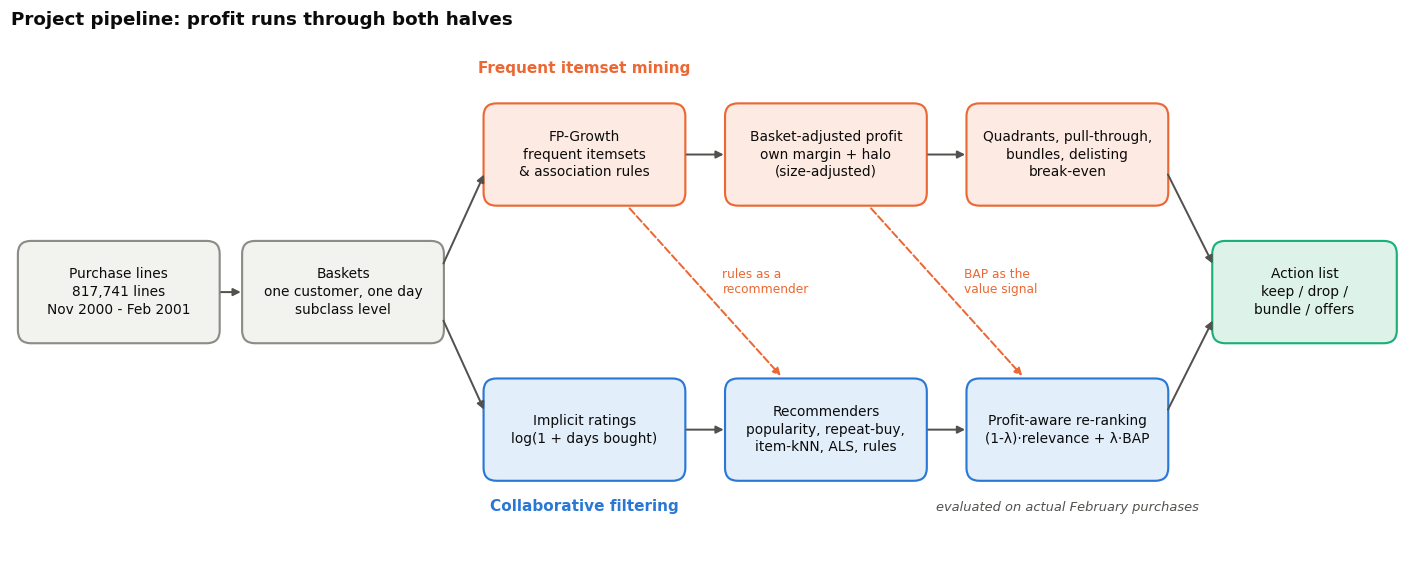

In [1]:
from src import plots
plots.pipeline_diagram();

<p style="text-align:center"><b>Figure 1.</b> Project pipeline linking frequent itemset mining and basket-adjusted profitability with collaborative filtering and profit-aware re-ranking. Dashed arrows indicate where outputs from the two components are reused.</p>

Model settings and re-ranking weights are selected using January validation results, with November–December as the validation training window. The selected models are then refitted on November–January and evaluated on February. Store-level BAP is also calculated on November–January and compared with February estimates to assess how consistently the measured patterns persist over time.

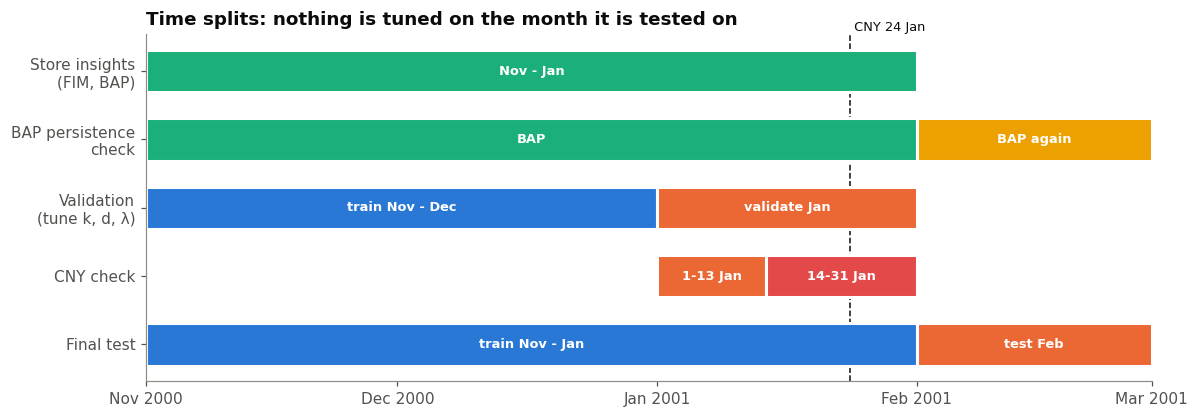

In [2]:
plots.timeline_diagram();

<p style="text-align:center"><b>Figure 2.</b> Temporal evaluation design. January is used for validation and February for the final test. Store insights are estimated on November–January, with February reserved for the out-of-time BAP comparison. The dashed line marks Chinese New Year (24 January 2001).</p>

## Data Source and Description

The Ta Feng Grocery Dataset contains 817,741 purchase lines from a Taiwanese supermarket between November 2000 and February 2001. The notebook loads the four monthly files (`D11`, `D12`, `D01`, `D02`) or the merged `ta_feng_all_months_merged.csv` file. The data is read directly from the shared folder on Jojie (`/mnt/data/public/tafeng`); no raw or processed data is copied into this submission. The original fields are renamed to a consistent schema for analysis. All monetary amounts are in New Taiwan dollars (NTD; shown as NT$ on chart axes).

| Column (original field) | Description |
|---|---|
| `date` (`TRANSACTION_DT`) | Transaction date |
| `customer` (`CUSTOMER_ID`) | Customer ID used to track purchase history |
| `age` (`AGE_GROUP`) | Age group, coded A–K in the monthly files |
| `area` (`PIN_CODE`) | Residence area, coded A–H |
| `subclass` (`PRODUCT_SUBCLASS`) | Product subclass used as the item level throughout the analysis |
| `product` (`PRODUCT_ID`) | Barcode-level product ID |
| `qty` (`AMOUNT`) | Quantity bought |
| `cost` (`ASSET`) | Store cost |
| `price` (`SALES_PRICE`) | Sales price |

There are no explicit ratings or product names, so recommendations use observed purchase behavior and results are reported by subclass code.

### Supplementary code

The `src/` folder contains the functions imported by this notebook.

| File | Contents |
|---|---|
| `src/data_prep.py` | Data loading, quality checks, cleaning, baskets, and time windows |
| `src/basket_mining.py` | FP-Growth, association rules, BAP, size-bias checks, delisting sensitivity, pull-through, bundles, and segment rules |
| `src/recommenders.py` | Utility matrix, popularity, repeat-buy, item-based kNN, implicit ALS, and FP-Growth rules recommender |
| `src/evaluation.py` | Time-split evaluation, precision/recall/NDCG@10, profit metrics, re-ranking, and λ selection |
| `src/plots.py` | Figures and diagrams saved in `figures/` |

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import display, Markdown

from src import data_prep as dp
from src import basket_mining as bm
from src import recommenders as rc
from src import evaluation as ev
from src import plots

pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)


def say(text):
    # results-driven narrative, so the text always matches the numbers;
    # "NT$" is written as "NTD" so Jupyter/MathJax do not read "$" as math
    display(Markdown(text.replace("NT$", "NTD ")))

### Settings

`DATA_DIR` identifies the Ta Feng data source. The loader accepts either the four monthly files or the merged Kaggle CSV. The date windows, minimum-support thresholds, and basket-count requirements are defined in the settings cell so that the analyses use consistent parameters.

In [4]:
DATA_DIR = "/mnt/data/public/tafeng"   # shared Ta Feng folder on Jojie (D11, D12, D01, D02)

MIN_SUPPORT = 0.003         # FP-Growth relative minimum support (0.3% of baskets)
MAX_ITEMSET = 3             # largest itemset mined
MIN_BAP_BASKETS = 30        # subclasses need >= 30 baskets for a BAP score
MIN_TRAIN_BASKETS = 2       # customers need >= 2 training baskets to be evaluated
SEGMENT_SUPPORT = 0.005     # relative support inside each segment
REC_RULE_SUPPORT = 0.001    # pair-rule support for the FP-Growth recommender (0.1%)
SEED = 0

# validation (tune) and test (report) windows
VAL_TRAIN_END, VAL_TEST_END = "2001-01-01", "2001-02-01"
TEST_TRAIN_END, TEST_END = "2001-02-01", "2001-03-01"
# January split used for the Chinese New Year check (CNY = 24 Jan 2001)
CNY_WINDOW_START = "2001-01-14"

print("pyFIM available:", bm.HAS_FIM)

pyFIM available: True


## Data Loading and Quality Checks

Before modeling, the data is checked for non-positive costs or prices, invalid quantities, returns, and sales below cost. The analysis also tests whether `price` and `cost` are line totals or unit values. This distinction matters because line profit is `price − cost` when both fields are line totals; if they were unit values, they would need to be multiplied by quantity first.

In [5]:
raw = dp.load_tafeng(DATA_DIR)
print(f"{len(raw):,} lines | {raw['customer'].nunique():,} customers | "
      f"{raw['subclass'].nunique():,} subclasses | "
      f"{raw['product'].nunique():,} products | "
      f"{raw['date'].min():%Y-%m-%d} to {raw['date'].max():%Y-%m-%d}")
raw.head()

817,741 lines | 32,266 customers | 2,012 subclasses | 23,812 products | 2000-11-01 to 2001-02-28


,date,customer,age,area,subclass,product,qty,cost,price
0,2000-11-01,46855,35-39,E,110411,4710085120468,3,51,57
1,2000-11-01,539166,40-44,E,130315,4714981010038,2,56,48
2,2000-11-01,663373,45-49,E,110217,4710265847666,1,180,135
3,2000-11-01,340625,<25,E,110411,4710085120697,1,17,24
4,2000-11-01,236645,35-39,H,712901,8999002568972,2,128,170


In [6]:
quality = dp.quality_report(raw)
quality

,lines,share
missing qty/cost/price,0,0.0000
qty <= 0 (returns),0,0.0000
cost <= 0,63,0.0001
price <= 0,0,0.0000
sold below cost (price < cost),62549,0.0765
cost > 5x price (likely error),4,0.0000
exact duplicate lines,0,0.0000


**Line totals or unit values?** If `price` and `cost` are line totals, their raw values should generally rise with quantity, while dividing each by quantity should reduce variation within a product. The opposite pattern would be more consistent with unit values. The following diagnostic compares both patterns before choosing the profit calculation.

In [7]:
lt = dp.line_total_check(raw)
display(lt)

is_total = (lt.loc["price", "median CV of value / qty"]
            < lt.loc["price", "median CV of raw value"]) and \
           (lt.loc["price", "median corr(qty, raw value)"] > 0.5)
say(f"Across {lt.attrs['products_used']:,} products with varying quantities, "
    f"`price / qty` varies far less than `price` "
    f"(median CV {lt.loc['price', 'median CV of value / qty']:.2f} vs "
    f"{lt.loc['price', 'median CV of raw value']:.2f}) and `price` tracks `qty` "
    f"(median correlation {lt.loc['price', 'median corr(qty, raw value)']:.2f}); "
    f"the same holds for `cost`. "
    + ("**Price and cost are line totals**, so line profit is `price − cost` "
       "without multiplying by quantity."
       if is_total else
       "**The test does not support line totals**; check this before "
       "trusting the profit figures."))

,median CV of raw value,median CV of value / qty,"median corr(qty, raw value)"
price,0.4634,0.0483,0.9915
cost,0.4665,0.0000,1.0000


Across 3,541 products with varying quantities, `price / qty` varies far less than `price` (median CV 0.05 vs 0.46) and `price` tracks `qty` (median correlation 0.99); the same holds for `cost`. **Price and cost are line totals**, so line profit is `price − cost` without multiplying by quantity.

In [8]:
lines = dp.clean(raw)
dropped = len(raw) - len(lines)
below_cost = (lines["profit"] < 0).mean()
caps = lines.attrs["caps"]
say(f"Cleaning removes **{dropped:,} lines ({dropped / len(raw):.2%})**: lines "
    f"with non-positive quantity, cost or price, a cost more than five times "
    f"the price, or a bulk quantity or price above the 99.95th percentile "
    f"(qty > {caps['qty']:,.0f} or price > NT${caps['price']:,.0f}), since a "
    f"few wholesale-sized lines would otherwise dominate the per-basket "
    f"averages. Lines sold below cost are kept on purpose: they are "
    f"**{below_cost:.1%}** of the clean lines and are exactly what this report "
    f"is about. Total clean revenue is NT${lines['price'].sum():,.0f} and "
    f"total profit NT${lines['profit'].sum():,.0f} "
    f"({lines['profit'].sum() / lines['price'].sum():.1%} margin).")

Cleaning removes **592 lines (0.07%)**: lines with non-positive quantity, cost or price, a cost more than five times the price, or a bulk quantity or price above the 99.95th percentile (qty > 24 or price > NTD 3,999), since a few wholesale-sized lines would otherwise dominate the per-basket averages. Lines sold below cost are kept on purpose: they are **7.7%** of the clean lines and are exactly what this report is about. Total clean revenue is NTD 102,704,292 and total profit NTD 15,771,483 (15.4% margin).

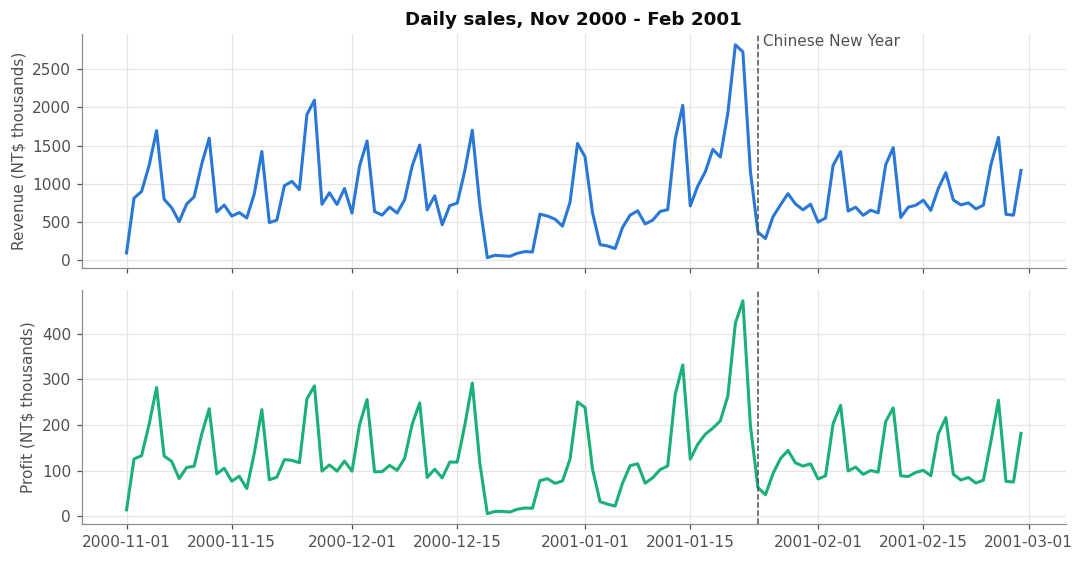

In [9]:
plots.daily_sales(lines);

<p style="text-align:center"><b>Figure 3.</b> Daily revenue and profit from November 2000 to February 2001. The dashed line marks Chinese New Year (24 January 2001).</p>

Revenue and profit vary over time, with an increase before Chinese New Year and a subsequent decline. Because January contains this seasonal pattern, the validation analysis checks whether the selected re-ranking weight changes when January is split into 1–13 January and 14–31 January.

In [10]:
daily = lines.groupby("date")["price"].sum()
daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max()), fill_value=0)
low = daily[daily < 0.2 * daily.median()]
if len(low):
    run_id = low.index.to_series().diff().dt.days.ne(1).cumsum().to_numpy()
    spans = [f"{g.index.min():%d %b %Y}" if len(g) == 1 else
             f"{g.index.min():%d %b}–{g.index.max():%d %b %Y}"
             for _, g in low.groupby(run_id)]
    say(f"Daily revenue falls below 20% of the median on **{len(low)} days** "
        f"({', '.join(spans)}). The data does not say why: a recording gap or a "
        f"store closure are both possible. These days are kept, since dropping "
        f"them would not change which items are bought together, but the "
        f"December (validation-training) window has fewer baskets as a result.")
else:
    say("No day has revenue below 20% of the median, so there is no sign of "
        "missing days in the data.")

Daily revenue falls below 20% of the median on **8 days** (01 Nov 2000, 19 Dec–25 Dec 2000). The data does not say why: a recording gap or a store closure are both possible. These days are kept, since dropping them would not change which items are bought together, but the December (validation-training) window has fewer baskets as a result.

## Building Baskets

Each basket represents **one customer on one day**, with purchases aggregated at the product-subclass level. Using subclasses (~2,000) rather than barcodes (~24,000) gives the mining and recommender models more observations per item, but it also hides differences between brands and pack sizes.

Store-level mining and BAP use November–January data. February is reserved for the final recommender evaluation and the out-of-time BAP comparison.

In [11]:
train_lines = dp.period(lines, end=TEST_TRAIN_END)      # Nov-Jan
hold_lines = dp.period(lines, start=TEST_TRAIN_END)     # Feb

item_basket, baskets = dp.make_baskets(train_lines)
db = dp.transactions(item_basket)
n_baskets = len(db)

summary = pd.Series({
    "baskets (Nov-Jan)": n_baskets,
    "customers": baskets["customer"].nunique(),
    "subclasses": item_basket["subclass"].nunique(),
    "mean subclasses per basket": baskets["size"].mean(),
    "median subclasses per basket": baskets["size"].median(),
    "mean basket profit (NTD)": baskets["profit"].mean(),
    "baskets per customer": n_baskets / baskets["customer"].nunique(),
})
summary.to_frame("value")

,value
baskets (Nov-Jan),"88,394.0000"
customers,"28,600.0000"
subclasses,"1,970.0000"
mean subclasses per basket,5.9753
median subclasses per basket,4.0000
mean basket profit (NTD),137.9271
baskets per customer,3.0907


## Frequent Itemset Mining and Association Rules

### Method

As in class, the **support** of an itemset $X$ is the number of baskets containing it, and its relative support is $relSup(X) = sup(X)/N$. For a rule $A \rightarrow B$,

$$
conf(A \rightarrow B) = \frac{sup(A \cup B)}{sup(A)}, \qquad
lift(A \rightarrow B) = \frac{conf(A \rightarrow B)}{relSup(B)}.
$$

Itemsets are mined with **FP-Growth** (`fim.fpgrowth`, as in class), since with ~2,000 subclasses Apriori's candidate generation would explode. Rules with one consequent are then generated from the frequent itemsets with the class `assoc` logic. The minimum support is 0.3% of baskets: low enough to reach pairs involving mid-selling subclasses, high enough that each rule rests on hundreds of baskets.

In [12]:
min_count = int(np.ceil(MIN_SUPPORT * n_baskets))
supports = bm.frequent_itemsets(db, min_count, zmax=MAX_ITEMSET)
rules = bm.assoc(supports, n_baskets)

by_size = pd.Series([len(k) for k in supports]).value_counts().sort_index()
print(f"min support = {min_count} baskets ({MIN_SUPPORT:.1%})")
print("frequent itemsets by size:", by_size.to_dict())
print(f"rules: {len(rules):,}")

min support = 266 baskets (0.3%)
frequent itemsets by size: {1: 364, 2: 684, 3: 18}
rules: 1,422


In [13]:
# most common pairs (support) and strongest rules (lift)
pairs = (rules[rules["n_ante"] == 1]
         .assign(pair=lambda d: [tuple(sorted((a[0], c)))
                                 for a, c in zip(d["antecedent"], d["consequent"])])
         .drop_duplicates("pair"))
display(pairs.nlargest(10, "support")[
    ["antecedent", "consequent", "support", "rel_support", "lift"]])
display(rules.head(10)[
    ["antecedent", "consequent", "support", "confidence", "lift"]])

,antecedent,consequent,support,rel_support,lift
217,"(100312,)",100205,2031,0.0230,3.4565
364,"(100201,)",100205,1888,0.0214,2.8561
669,"(110401,)",100205,1697,0.0192,1.9621
438,"(130206,)",130204,1665,0.0188,2.5836
464,"(100102,)",100205,1440,0.0163,2.5373
1058,"(130206,)",100205,1375,0.0156,1.4830
1150,"(130204,)",100205,1304,0.0148,1.4022
1202,"(500201,)",100205,1296,0.0147,1.3584
274,"(500210,)",500201,1232,0.0139,3.2454
657,"(100205,)",100505,1216,0.0138,1.9899


,antecedent,consequent,support,confidence,lift
0,"(320402,)",320501,399,0.5808,61.4091
1,"(320501,)",320402,399,0.4773,61.4091
2,"(100403,)",100402,279,0.2298,17.2450
3,"(100402,)",100403,279,0.2368,17.2450
4,"(530505,)",530302,343,0.3500,13.9486
5,"(530302,)",530505,343,0.1546,13.9486
6,"(110504,)",110502,290,0.1473,12.5302
7,"(110502,)",110504,290,0.2791,12.5302
8,"(560405,)",560402,447,0.4170,11.4183
9,"(560402,)",560405,447,0.1385,11.4183


In [14]:
max_fi = bm.maximal(supports)
top_pair = pairs.nlargest(1, "support").iloc[0]
top_rule = rules.iloc[0]
say(f"FP-Growth finds **{len(supports):,} frequent itemsets** "
    f"({by_size.get(2, 0):,} pairs, {by_size.get(3, 0):,} triples) and "
    f"**{len(max_fi):,} maximal itemsets** of two or more subclasses. "
    f"The most common pair is {top_pair['pair']} "
    f"({top_pair['rel_support']:.1%} of baskets, lift {top_pair['lift']:.2f}). "
    f"The strongest rule is {top_rule['antecedent']} → {top_rule['consequent']} "
    f"(confidence {top_rule['confidence']:.2f}, lift {top_rule['lift']:.2f}). "
    f"Confidences are modest, as is typical of grocery data: even strong "
    f"complements appear together in only a fraction of baskets, which is why "
    f"lift rather than confidence is used to rank rules.")

FP-Growth finds **1,066 frequent itemsets** (684 pairs, 18 triples) and **668 maximal itemsets** of two or more subclasses. The most common pair is ('100205', '100312') (2.3% of baskets, lift 3.46). The strongest rule is ('320402',) → 320501 (confidence 0.58, lift 61.41). Confidences are modest, as is typical of grocery data: even strong complements appear together in only a fraction of baskets, which is why lift rather than confidence is used to rank rules.

Association rules describe which subclasses are bought together, but they do not measure economic value. The next section combines own-item profit with a basket-size benchmark to examine how the profit of the remaining items differs in baskets containing each subclass.

## Basket-Adjusted Profit

### Method

For subclass $i$ in basket $b$, let $p_{ib}$ be its own profit, $P_b$ the total profit of the basket, and $n_b$ the number of distinct subclasses in the basket. Define:

- **Own margin**: $m_i=\frac{1}{|B_i|}\sum_{b\in B_i}p_{ib}$, the average own-item profit per basket containing subclass $i$.
- **Other-item profit**: $o_{ib}=P_b-p_{ib}$, the total profit from the other subclasses in basket $b$.

To account for basket size, the analysis compares other-item profit with a proportional benchmark:

$$
E_n=\operatorname{mean}_{b:n_b=n}\left[P_b\frac{n_b-1}{n_b}\right].
$$

The benchmark assumes that basket profit is allocated proportionally across the distinct subclasses. It is a modeling assumption, not a direct estimate of the profit that would remain if an item were removed. The **halo** and **basket-adjusted profit (BAP)** are then

$$
h_i=\frac{1}{|B_i|}\sum_{b\in B_i}(o_{ib}-E_{n_b}),\qquad \operatorname{BAP}_i=m_i+h_i.
$$

Within each basket-size group, the residuals sum to zero across item occurrences by construction. A positive halo therefore indicates above-benchmark profit from the other items in the subclass's observed baskets, not profit caused by the subclass. Basket sizes above 25 are pooled, and only subclasses appearing in at least 30 training baskets receive an individual score. Each halo also has a standard error, which helps indicate how uncertain the estimate is.

Subclasses are classified using own margin and whether the halo is above the median:

| | **Halo above median** | **Halo at or below median** |
|---|---|---|
| **Own margin > 0** | **Star:** profitable, with an above-median halo | **Passenger:** profitable, with a lower halo |
| **Own margin ≤ 0** | **Loss leader:** non-positive own margin, with an above-median halo | **Dead weight:** non-positive own margin, with a lower halo |

These labels are descriptive categories, not causal conclusions.

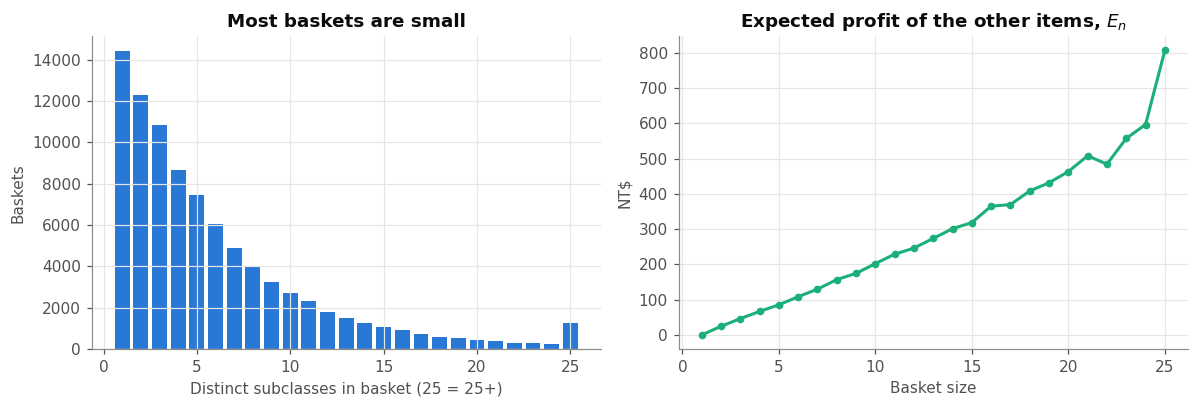

In [15]:
bap = bm.basket_adjusted_profit(item_basket, baskets,
                                min_baskets=MIN_BAP_BASKETS)
plots.basket_baseline(baskets, bap.attrs["expected_other"]);

<p style="text-align:center"><b>Figure 4.</b> Left: distribution of basket sizes. Right: the proportional benchmark $E_n$ used to calculate halo. The benchmark adjusts for basket size and is an assumption about how basket profit is distributed across subclasses.</p>

,subclasses,revenue,own_profit,median_margin,median_halo,revenue_share,own_profit_share
quadrant,,,,,,,
Star,560.0000,"19,461,214.0000","4,254,884.0000",37.4319,72.9602,0.2561,0.3664
Loss leader,0.0000,0.0000,0.0000,NaN,NaN,0.0000,0.0000
Passenger,556.0000,"54,459,017.0000","7,523,198.0000",18.2869,-0.6104,0.7167,0.6478
Dead weight,5.0000,"2,069,319.0000","-165,421.0000",-8.6961,-18.1540,0.0272,-0.0142


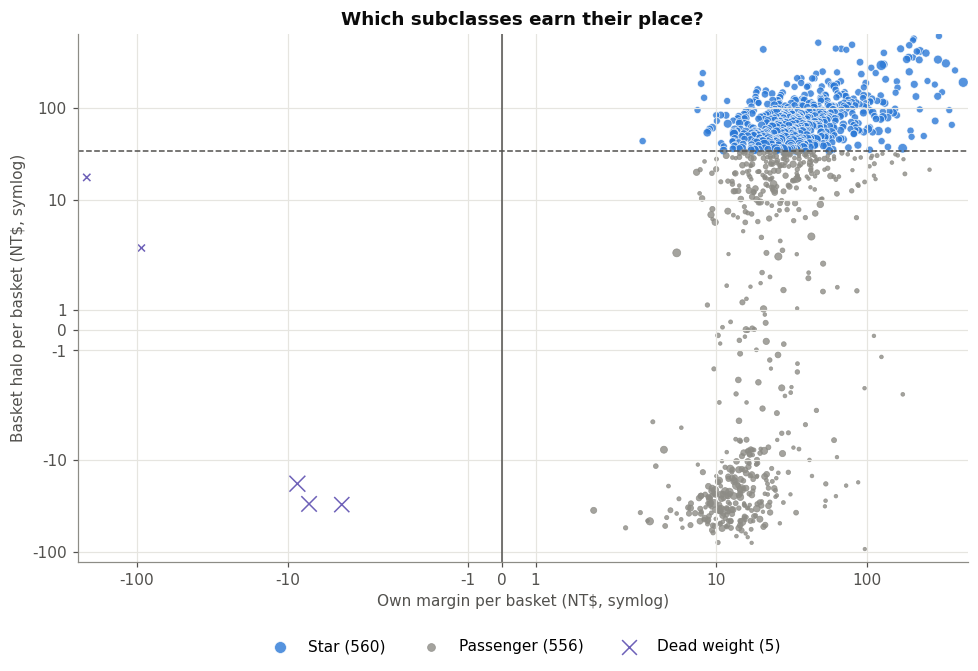

In [16]:
quad = bm.quadrant_summary(bap)
display(quad)
plots.quadrant_map(bap);

<p style="text-align:center"><b>Figure 5.</b> Own margin against basket halo for scored subclasses. Marker size represents the number of baskets; the vertical line marks zero margin, and the dashed line marks the median halo.</p>

In [17]:
loss_subclasses = bap[bap["own_margin"] <= 0]
line_loss_share = (lines["profit"] < 0).mean()
few = len(loss_subclasses) < 0.05 * len(bap)
say(f"**{len(bap):,} subclasses** have enough baskets for a BAP score: "
    f"{int(quad.loc['Star', 'subclasses']):,} stars, "
    f"{int(quad.loc['Passenger', 'subclasses']):,} passengers, and only "
    f"**{len(loss_subclasses):,} that lose money on average**, even though "
    f"{line_loss_share:.1%} of all purchase lines are sold below cost. "
    + ("Losses are therefore concentrated on particular *sales* rather than on "
       "whole categories (the data does not record whether a sale was a "
       "promotion, markdown or clearance), so asking which subclasses are loss "
       "leaders misses almost all of them. The next section asks the game "
       "plan's question where the losses actually happen."
       if few else
       "The next section also looks at the individual below-cost sales, where "
       "most of the store's losses happen."))

**1,121 subclasses** have enough baskets for a BAP score: 560 stars, 556 passengers, and only **5 that lose money on average**, even though 7.7% of all purchase lines are sold below cost. Losses are therefore concentrated on particular *sales* rather than on whole categories (the data does not record whether a sale was a promotion, markdown or clearance), so asking which subclasses are loss leaders misses almost all of them. The next section asks the game plan's question where the losses actually happen.

### Loss-making sales: where the loss leaders really are

A subclass can be profitable overall while some of its sales occur below cost. The analysis therefore recalculates BAP using only baskets in which that subclass was sold at a loss. Own margin is negative for these below-cost sales by definition; the halo measures whether the other items in those baskets earn more or less than the size-adjusted benchmark, which is based on all baskets.

The halo is compared with the same median-halo threshold used in the all-sales analysis. A below-cost sale is classified as a loss leader when its halo is above that threshold and as dead weight when it is at or below it. The dataset does not identify whether below-cost sales came from a promotion, markdown, clearance, or another pricing decision, so these labels describe the observed transactions rather than confirmed promotion effects.

,subclasses,below-cost baskets,own loss (NTD),median halo (NTD)
Loss leader,3,230,3313,40.8659
Dead weight,121,35202,614236,-41.5927


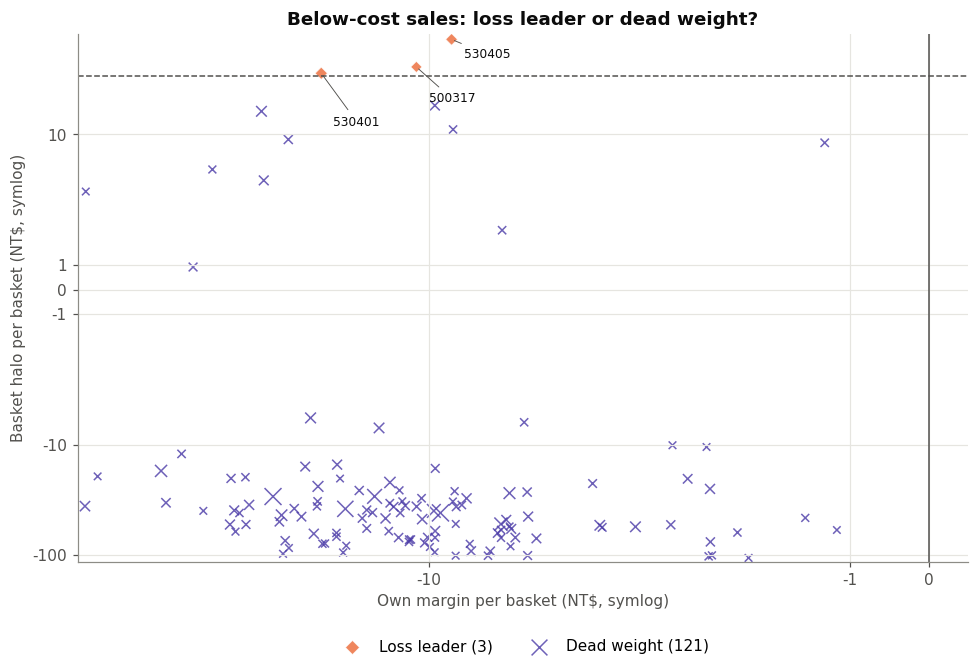

In [18]:
bap_loss = bm.basket_adjusted_profit(item_basket, baskets,
                                     min_baskets=MIN_BAP_BASKETS, sales="loss",
                                     halo_ref=bap.attrs["halo_median"])
lead = bap_loss[bap_loss["quadrant"] == "Loss leader"]
dead = bap_loss[bap_loss["quadrant"] == "Dead weight"]
loss_view = pd.DataFrame({
    "subclasses": [len(lead), len(dead)],
    "below-cost baskets": [lead["n_baskets"].sum(), dead["n_baskets"].sum()],
    "own loss (NTD)": [-lead["profit"].sum(), -dead["profit"].sum()],
    "median halo (NTD)": [lead["halo"].median(), dead["halo"].median()],
}, index=["Loss leader", "Dead weight"])
display(loss_view)
plots.quadrant_map(bap_loss, title="Below-cost sales: loss leader or dead weight?",
                   name="03c_loss_sales");

<p style="text-align:center"><b>Figure 6.</b> Below-cost sales by subclass, showing own margin on those sales against the halo of the baskets they were in. The dashed line marks the median halo used in the all-sales view; diamonds and crosses identify the loss-leader and dead-weight classifications.</p>

In [19]:
say(f"**{len(bap_loss):,} subclasses** were sold below cost in at least "
    f"{MIN_BAP_BASKETS} baskets. On own margin alone, every one of these sales "
    f"looks like a loss to stop. The halo splits them: **{len(lead):,} are loss "
    f"leaders**, and **{(lead['bap'] > 0).sum():,} of those have a positive BAP**, "
    f"meaning their measured halo exceeds their own loss "
    f"({(lead['halo_t'] >= 2).sum():,} with a halo at least two standard errors "
    f"above zero). **{len(dead):,} are dead weight**: their below-cost sales lost "
    f"NT${-dead['profit'].sum():,.0f} over November–January in baskets that "
    f"earned no more than a typical item's.")

**124 subclasses** were sold below cost in at least 30 baskets. On own margin alone, every one of these sales looks like a loss to stop. The halo splits them: **3 are loss leaders**, and **3 of those have a positive BAP**, meaning their measured halo exceeds their own loss (0 with a halo at least two standard errors above zero). **121 are dead weight**: their below-cost sales lost NTD 614,236 over November–January in baskets that earned no more than a typical item's.

In [20]:
cols = ["n_baskets", "own_margin", "margin_rate", "halo", "halo_se",
        "halo_t", "bap"]
print("Loss leaders (below-cost sales) with the largest BAP")
display(lead.sort_values("bap", ascending=False)[cols].head(10))
print("Dead weight (below-cost sales) with the most negative BAP")
display(dead.sort_values("bap")[cols].head(10))

Loss leaders (below-cost sales) with the largest BAP


,n_baskets,own_margin,margin_rate,halo,halo_se,halo_t,bap
subclass,,,,,,,
530405,74,-8.6216,-0.0932,72.7503,103.4444,0.7033,64.1287
500317,50,-10.8400,-0.1193,40.8659,35.4019,1.1543,30.0259
530401,106,-20.1226,-0.0903,35.7804,18.0925,1.9776,15.6578


Dead weight (below-cost sales) with the most negative BAP


,n_baskets,own_margin,margin_rate,halo,halo_se,halo_t,bap
subclass,,,,,,,
560402,340,-93.5794,-0.1209,-36.0220,10.2321,-3.5205,-129.6014
100510,41,-25.8049,-0.1536,-97.7107,19.3233,-5.0566,-123.5156
100504,53,-17.4528,-0.1032,-95.1381,16.1288,-5.8987,-112.5909
110506,35,-24.8286,-0.1176,-86.4944,15.6522,-5.5260,-111.3230
100503,38,-8.3947,-0.0743,-101.6052,18.4273,-5.5138,-109.9999
110305,38,-2.2895,-0.0256,-106.4811,21.9765,-4.8452,-108.7706
100310,66,-6.8030,-0.0508,-101.6157,22.8828,-4.4407,-108.4187
130102,113,-5.2566,-0.1115,-101.3104,13.5828,-7.4587,-106.5670
130207,64,-2.7969,-0.0873,-103.0122,14.4610,-7.1234,-105.8091


**Why are baskets with below-cost sales less profitable?** Almost all below-cost sales sit in baskets that earn *less* than baskets of the same size, the opposite of a loss-leader pattern. The data cannot say why, but two explanations are consistent with it:

* **Cherry-picking.** Shoppers who buy items below cost may also concentrate on other discounted or low-margin items, so the rest of their basket earns less.
* **Overlapping price events.** Below-cost sales may coincide with periods when many items are discounted at once, lowering the margin of the whole basket.

Either way, the evidence here does not support keeping below-cost sales for the sake of the basket. Telling the two explanations apart would need promotion calendars or a controlled price test.

### Why the size baseline matters

A naive halo compares the other items in a subclass's baskets with the store-wide average. This can confound the item's association with basket profitability and the fact that the item tends to appear in larger baskets. The size-adjusted benchmark instead varies with basket size. The following plot compares both halo measures with average basket size to show how the adjustment changes that relationship.

,value
"spearman(avg size, naive halo)",0.6235
"spearman(avg size, adjusted halo)",0.1266


size-adjusted quadrant,Dead weight,Passenger,Star
naive quadrant,,,
Dead weight,5,0,0
Passenger,0,453,103
Star,0,103,457


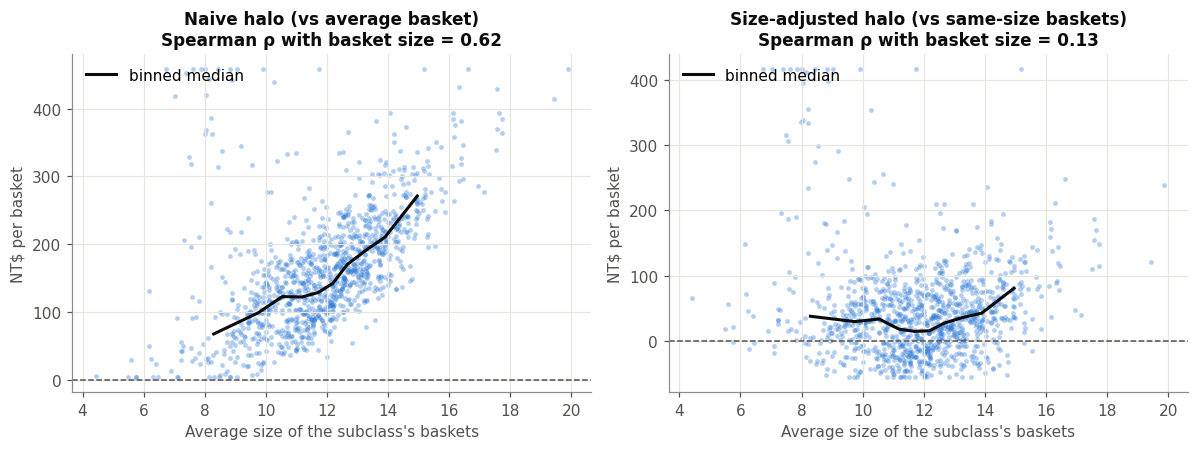

In [21]:
bias, relabel = bm.size_bias_check(bap)
display(bias.to_frame("value"))
display(relabel)
plots.size_bias(bap, bias);

<p style="text-align:center"><b>Figure 7.</b> Naive and size-adjusted halo against average basket size by subclass. Black points show binned medians; values outside the 1st and 99th percentiles are clipped for display.</p>

In [22]:
same = sum(relabel.at[q, q] for q in relabel.index if q in relabel.columns)
flips = int(relabel.values.sum() - same)
say(f"The naive halo tracks basket size (Spearman ρ = {bias.iloc[0]:.2f}), so on "
    f"its own it largely says *which items are bought on big trips*. After "
    f"comparing with same-size baskets the link drops to ρ = {bias.iloc[1]:.2f}. "
    f"The correction changes decisions: **{flips:,} of the {len(bap):,} scored "
    f"subclasses ({flips / len(bap):.0%}) would land in a different quadrant** "
    f"under the naive halo.")

The naive halo tracks basket size (Spearman ρ = 0.62), so on its own it largely says *which items are bought on big trips*. After comparing with same-size baskets the link drops to ρ = 0.13. The correction changes decisions: **206 of the 1,121 scored subclasses (18%) would land in a different quadrant** under the naive halo.

### Does the halo persist out of time?

BAP is estimated on November–January data and recalculated using February baskets. Comparing subclass rankings across the two periods assesses whether the measured own margins and halos persist out of time. Similar rankings support further investigation, but do not establish that a halo is causal or will remain stable indefinitely.

,Nov-Jan vs Feb
own_margin,0.8970
halo,0.7855
bap,0.8309
same_quadrant,0.7652
subclasses,643.0000


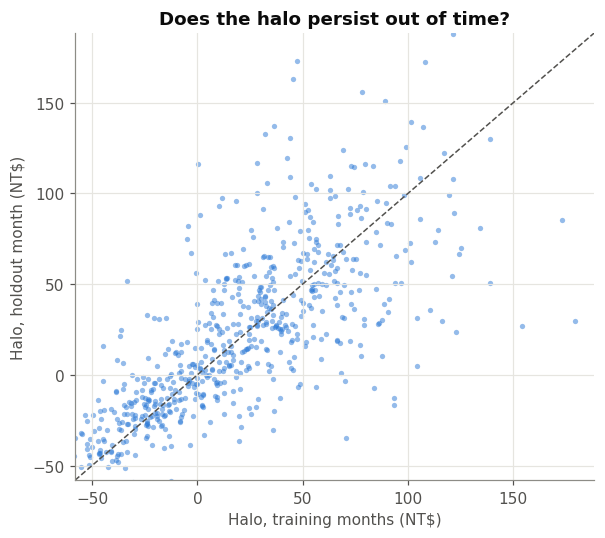

In [23]:
hold_ib, hold_bk = dp.make_baskets(hold_lines)
bap_hold = bm.basket_adjusted_profit(hold_ib, hold_bk,
                                     min_baskets=MIN_BAP_BASKETS)
persist = bm.bap_persistence(bap, bap_hold)
display(persist.to_frame("Nov-Jan vs Feb"))
plots.bap_persistence(bap, bap_hold);

<p style="text-align:center"><b>Figure 8.</b> Halo of each subclass in November–January against its halo recomputed on February alone. Points near the dashed diagonal kept their halo out of time.</p>

In [24]:
say(f"On the {int(persist['subclasses']):,} subclasses scored in both periods, "
    f"the Spearman correlation between training and February is "
    f"{persist['own_margin']:.2f} for own margin, "
    f"**{persist['halo']:.2f} for the halo** and {persist['bap']:.2f} for BAP, "
    f"and {persist['same_quadrant']:.0%} of subclasses stay in the same "
    f"quadrant. "
    + ("The halo ranking is fairly stable out of time, which supports using it "
       "to prioritise reviews, though not as proof of a causal effect."
       if persist["halo"] >= 0.5 else
       "The halo is only moderately stable month to month, so decisions "
       "should favour subclasses whose halo is also statistically strong."))

On the 643 subclasses scored in both periods, the Spearman correlation between training and February is 0.90 for own margin, **0.79 for the halo** and 0.83 for BAP, and 77% of subclasses stay in the same quadrant. The halo ranking is fairly stable out of time, which supports using it to prioritise reviews, though not as proof of a causal effect.

### Which subclasses are associated with a loss leader?

FP-Growth rules identify profitable subclasses that appear more frequently in baskets containing a below-cost loss leader. Pair rules are mined at 0.1% support to include less common associations. For a rule $i \rightarrow j$, the analysis estimates the difference in subclass $j$'s own-profit contribution relative to its overall prevalence:

$$\Delta_j = \left[\operatorname{conf}(i \rightarrow j) - \operatorname{relSup}(j)\right] m_j$$

where $m_j$ is the average own profit of subclass $j$. This is an association-based estimate, not incremental profit caused by the loss leader. The rules use all baskets containing the leader, not only baskets where it was sold below cost.

In [25]:
pair_rules_train = bm.assoc(bm.frequent_itemsets(
    db, int(np.ceil(REC_RULE_SUPPORT * n_baskets)), zmax=2), n_baskets)
pull = bm.pull_through(pair_rules_train, bap, leaders=bap_loss)
pull.head(15)

,leader,leader_margin,consequent,cons_margin,confidence,lift,extra_profit
0,530401,-20.1226,530110,34.2893,0.1803,4.2700,4.7352
1,530401,-20.1226,530101,25.8740,0.2277,3.9988,4.4180
2,530401,-20.1226,500201,5.5189,0.2441,2.7821,0.8629
3,530401,-20.1226,100205,14.8159,0.1658,1.3473,0.6330
4,530405,-8.6216,530110,34.2893,0.1515,3.5868,3.7458
5,530405,-8.6216,530101,25.8740,0.1940,3.4066,3.5455
6,530405,-8.6216,530404,24.4115,0.1535,5.2888,3.0393
7,530405,-8.6216,530114,32.3857,0.1179,3.6874,2.7825
8,530405,-8.6216,530403,19.6785,0.1583,5.6523,2.5644


2 of the 3 loss leaders have at least one pair rule pointing to a profitable subclass. For the rest, the halo is spread across many items, none frequent enough on its own to pass the support threshold.

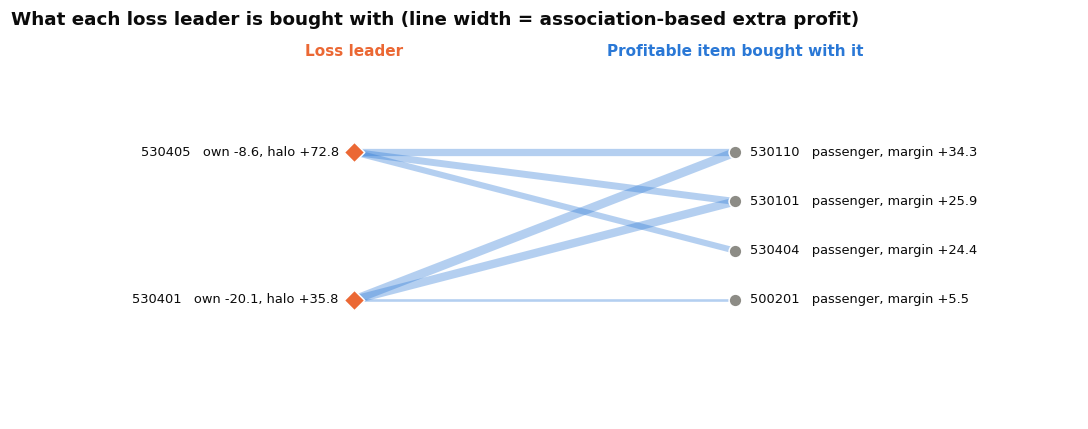

<p style="text-align:center"><b>Figure 9.</b> Loss leaders (left, with own margin and halo per basket on their below-cost sales) linked to the profitable subclasses they are bought with (right, coloured by quadrant). Line width is the association-based extra profit per leader basket, $\Delta_j$; up to three links per leader are drawn.</p>

In [26]:
import matplotlib.pyplot as plt

if len(pull):
    by_leader = pull.groupby("leader")["extra_profit"].sum()
    covered = by_leader.reindex(lead.index).fillna(0)
    say(f"{(covered > 0).sum():,} of the {len(lead):,} loss leaders have at "
        f"least one pair rule pointing to a profitable subclass. "
        f"For the rest, the halo is spread across many items, none frequent "
        f"enough on its own to pass the support threshold.")
    fig = plots.pull_network(pull, bap, leaders=bap_loss)
    display(fig)
    plt.close(fig)
    say('<p style="text-align:center"><b>Figure 9.</b> Loss leaders (left, with '
        'own margin and halo per basket on their below-cost sales) linked to the '
        'profitable subclasses they are bought with (right, coloured by quadrant). '
        'Line width is the association-based extra profit per leader basket, $\\Delta_j$; up to three '
        'links per leader are drawn.</p>')
else:
    say("No loss leader has a pair rule at this support threshold: their halos "
        "are spread across many low-support items, so there is no pull-through "
        "map to draw (Figure 9 is omitted).")

### What would ending below-cost sales really save?

The own loss on a below-cost sale is observed, but the causal effect of that sale on the rest of the basket is unknown. The analysis therefore varies the assumed causal share $c$ of a positive halo. Under this scenario, the modeled profit change from stopping below-cost sales of subclass $i$ is

$$
\Delta_i(c)=-n_i m_i-c\,n_i\max(h_i,0),
$$

where $n_i$ is the number of baskets containing a below-cost sale, $m_i$ is the own margin on those sales, and $h_i$ is their measured halo. The first term is the own loss avoided; the second is the halo assumed to be lost if it is causal.

Two rules are compared over causal shares from 0% to 100%:

- **Margin rule:** stop every below-cost sale.
- **BAP rule:** stop only below-cost sales with negative BAP.

For a subclass with positive halo, the break-even share is $-m_i/h_i$. It indicates how much of the measured halo would need to be causal for keeping the below-cost sales to be worthwhile under this model. This is a sensitivity analysis, not an estimate of the true causal share.

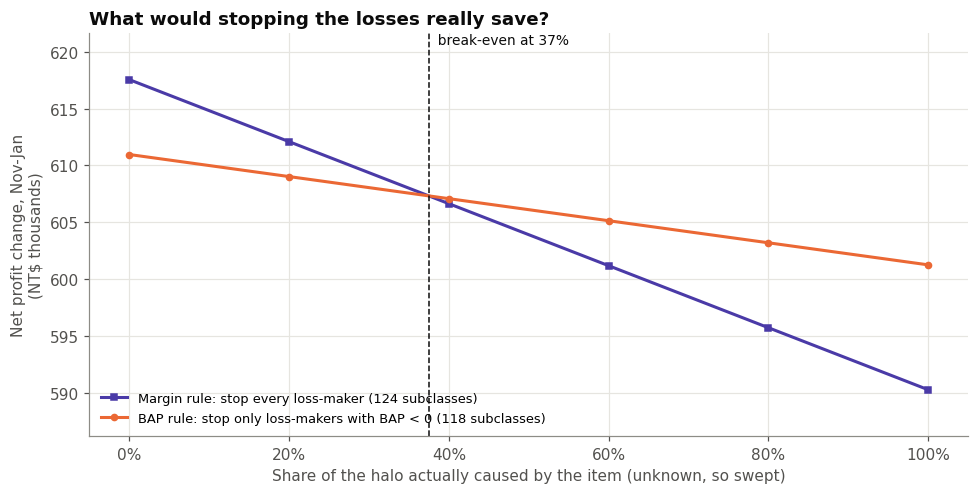

In [27]:
curves, crossover = bm.delisting_scenarios(bap_loss)
plots.delisting(curves, crossover);

<p style="text-align:center"><b>Figure 10.</b> Modeled net profit change from the margin and BAP rules over November–January as the assumed causal share of the halo varies from 0% to 100%. The dashed line marks the aggregate break-even share at which the two rules have equal modeled outcomes.</p>

In [28]:
at = lambda rule, c: curves[(curves["rule"].str.startswith(rule))
                            & np.isclose(curves["causal_share"], c)]["net_profit"].iloc[0]
kept_n = curves.attrs["kept_n"]
txt = (f"Stopping every below-cost sale would remove **NT${at('Margin', 0):,.0f}** "
       f"of visible losses over November–January. ")
if kept_n and crossover is not None:
    full = at("Margin", 1)
    txt += (f"But {kept_n:,} subclasses have below-cost sales with BAP ≥ 0: "
            f"together those sales lose NT${curves.attrs['kept_saved']:,.0f}, while "
            f"their baskets earn NT${curves.attrs['kept_at_risk']:,.0f} more than "
            f"baskets of the same size. So the margin rule only comes out ahead if "
            f"**less than {crossover:.0%} of that halo is truly caused by those "
            f"below-cost sales**. Even if all of it is causal, stopping every "
            f"below-cost sale would " + (f"lose NT${-full:,.0f} in this model. "
                                        if full < 0 else
                                        f"still gain NT${full:,.0f} in this model. "))
else:
    txt += ("No subclass's below-cost sales have a non-negative BAP, so the two "
            "rules select the same sales. ")
txt += (f"The BAP rule stops only the below-cost sales with negative BAP and gains "
        f"between NT${at('BAP', 1):,.0f} and NT${at('BAP', 0):,.0f} whatever the "
        f"causal share, so its modeled outcome is less sensitive to the unknown "
        f"causal share. The difference between the two rules is small relative "
        f"to the total loss, because almost all below-cost losses have negative BAP.")
say(txt)

Stopping every below-cost sale would remove **NTD 617,549** of visible losses over November–January. But 6 subclasses have below-cost sales with BAP ≥ 0: together those sales lose NTD 6,591, while their baskets earn NTD 17,585 more than baskets of the same size. So the margin rule only comes out ahead if **less than 37% of that halo is truly caused by those below-cost sales**. Even if all of it is causal, stopping every below-cost sale would still gain NTD 590,249 in this model. The BAP rule stops only the below-cost sales with negative BAP and gains between NTD 601,243 and NTD 610,958 whatever the causal share, so its modeled outcome is less sensitive to the unknown causal share. The difference between the two rules is small relative to the total loss, because almost all below-cost losses have negative BAP.

### Bundles and shelf placement

Candidate bundles are pairs with lift of at least 1.5 and positive combined own margin. They are ranked by $\text{lift} \times (m_a + m_b) \times \text{support}$, combining association strength, combined item-level profitability, and frequency. These are candidates for a controlled bundle or placement test, not evidence that bundling will increase sales or profit.

In [29]:
bundles = bm.bundle_pairs(rules, bap, min_lift=1.5)
bundles.head(10)

,a,b,quad_a,quad_b,support,lift,margin_a,margin_b,pair_margin,score
0,320402,320501,Star,Star,399,61.4091,430.5531,123.8194,554.3725,"13,583,361.1735"
1,560201,560402,Passenger,Passenger,1073,6.0346,42.7531,48.9563,91.7095,"593,831.2216"
2,530110,530114,Passenger,Passenger,848,7.1054,34.2893,32.3857,66.6750,"401,742.2160"
3,530101,530103,Passenger,Passenger,1047,7.4447,25.8740,16.5955,42.4696,"331,032.1783"
4,560402,560405,Passenger,Passenger,447,11.4183,48.9563,15.3787,64.3351,"328,365.2357"
5,530104,530105,Star,Passenger,731,7.8150,31.0767,24.0660,55.1426,"315,016.7878"
6,530110,530111,Passenger,Passenger,370,10.4053,34.2893,34.3432,68.6325,"264,232.5025"
7,560201,560204,Passenger,Passenger,692,5.9399,42.7531,11.7121,54.4652,"223,874.0949"
8,100402,100403,Passenger,Passenger,279,17.2450,13.1282,33.3633,46.4914,"223,686.7522"
9,120103,120104,Passenger,Passenger,636,9.0104,14.9442,22.8402,37.7845,"216,527.5263"


## Recommender System

### Implicit utility matrix

The dataset has no explicit ratings, so the utility matrix represents observed repeat purchasing. For customer $u$ and subclass $i$, the implicit signal is

$$r_{ui}=\log\left(1+\text{number of distinct days }u\text{ bought }i\right).$$

Counting purchase days rather than units reduces the influence of bulk purchases, while the log transformation dampens the effect of frequent repeat purchases. An empty cell means there was no recorded purchase during the observation window; it is not an explicit negative rating.

### Models

* **Popularity:** ranks subclasses by number of buyers and recommends the same list to everyone.
* **Repeat-buy:** ranks a customer's previously purchased subclasses using $r_{ui}$. It is a non-collaborative baseline, but an important one for grocery shopping where repeat purchases are common.
* **Item-based kNN:** uses cosine similarity between item purchase-history columns and scores candidates by the sum of similarity-weighted purchase signals:
$$\hat r_{ui}=\sum_{j\in N_k(i)\cap I_u}\operatorname{sim}(i,j)r_{uj}.$$


The implementation uses the sum rather than dividing by the sum of similarities, preserving the magnitude of accumulated neighbor evidence. The matrix is not mean-centered because the signals are positive-only purchase counts.
* **Implicit ALS:** learns customer and item factors from implicit preferences $p_{ui}=\mathbb{1}[r_{ui}>0]$ and confidence weights $c_{ui}=1+\alpha r_{ui}$, following Hu, Koren, and Volinsky (2008).
* **FP-Growth rules:** scores candidate subclasses using pair rules triggered by a customer's purchase history. This tests whether the same associations used to describe baskets can also rank subsequent purchases.

### Evaluation protocol

Models are trained on an earlier period and evaluated on a later one. A customer is included if they have at least two training baskets and at least one purchase in the test window. The top 10 recommendations are evaluated using precision@10, recall@10, NDCG@10, and catalogue coverage.

Two settings are evaluated:

* **All items:** previously purchased subclasses remain eligible for recommendation.
* **New items:** subclasses purchased during training are removed from both the recommendation list and the test ground truth, measuring discovery of items new to the customer.

In [30]:
# validation window: train Nov-Dec, test Jan
val_train = dp.period(lines, end=VAL_TRAIN_END)
val_test = dp.period(lines, VAL_TRAIN_END, VAL_TEST_END)
val_ib, val_bk = dp.make_baskets(val_train)
R_val, users_val, items_val = rc.build_utility(val_train)
nb_val = val_bk.groupby("customer").size()
test_val = ev.TestSet(R_val, users_val, items_val, val_test, nb_val,
                      MIN_TRAIN_BASKETS)

density = R_val.nnz / np.prod(R_val.shape)
say(f"The validation utility matrix has **{R_val.shape[0]:,} customers × "
    f"{R_val.shape[1]:,} subclasses** with {R_val.nnz:,} non-empty cells "
    f"(density {density:.2%}). **{len(test_val.customers):,} customers** have "
    f"at least {MIN_TRAIN_BASKETS} baskets in November–December and buy "
    f"again in January; they form the validation set.")

The validation utility matrix has **23,579 customers × 1,904 subclasses** with 305,044 non-empty cells (density 0.68%). **7,769 customers** have at least 2 baskets in November–December and buy again in January; they form the validation set.

### Tuning on November–December → January

Model settings and re-ranking weights are selected on January validation data using November–December purchase histories. February is reserved for the final out-of-time test.

In [31]:
knn_grid = [rc.ItemKNN(k).fit(R_val) for k in [10, 25, 50, 100, 200]]
als_grid = [rc.ImplicitALS(d, alpha=a, seed=SEED).fit(R_val)
            for d, a in [(16, 10), (32, 10), (64, 10), (32, 3), (32, 30)]]
grid = ev.evaluate_models(knn_grid + als_grid, test_val)
grid_wide = grid.pivot(index="model", columns="mode",
                       values=["ndcg@10", "recall@10"])
# flatten the two-level header so every lookup returns a plain number
grid_wide.columns = [f"{metric} ({mode})" for metric, mode in grid_wide.columns]
grid_wide["mean ndcg"] = grid_wide[["ndcg@10 (all)", "ndcg@10 (new)"]].mean(axis=1)
grid_wide.sort_values("mean ndcg", ascending=False)

,ndcg@10 (all),ndcg@10 (new),recall@10 (all),recall@10 (new),mean ndcg
model,,,,,
Item-kNN (k=200),0.1762,0.1455,0.1410,0.1401,0.1608
Item-kNN (k=100),0.1763,0.1450,0.1406,0.1384,0.1607
Item-kNN (k=50),0.1720,0.1425,0.1358,0.1352,0.1573
"Implicit ALS (d=16, alpha=10)",0.1930,0.1146,0.1601,0.1077,0.1538
"Implicit ALS (d=32, alpha=3)",0.2174,0.0901,0.1671,0.0814,0.1538
Item-kNN (k=25),0.1671,0.1370,0.1322,0.1291,0.1520
"Implicit ALS (d=32, alpha=10)",0.1960,0.0940,0.1612,0.0868,0.1450
"Implicit ALS (d=64, alpha=10)",0.2054,0.0744,0.1694,0.0682,0.1399
Item-kNN (k=10),0.1559,0.1231,0.1242,0.1161,0.1395


In [32]:
best_name = grid_wide["mean ndcg"].idxmax()
best_val = next(m for m in knn_grid + als_grid if m.name == best_name)
best_knn = max(knn_grid, key=lambda m: float(grid_wide.at[m.name, "mean ndcg"]))
best_als = max(als_grid, key=lambda m: float(grid_wide.at[m.name, "mean ndcg"]))
print("best item-kNN:", best_knn.name)
print("best ALS     :", best_als.name)
print("selected CF model (mean NDCG over both modes):", best_name)

best item-kNN: Item-kNN (k=200)
best ALS     : Implicit ALS (d=16, alpha=10)
selected CF model (mean NDCG over both modes): Item-kNN (k=200)


In [33]:
# pair rules mined on the validation-training baskets only (Nov-Dec)
val_db = dp.transactions(val_ib)
val_rules = bm.assoc(bm.frequent_itemsets(
    val_db, int(np.ceil(REC_RULE_SUPPORT * len(val_db))), zmax=2), len(val_db))
rules_val = rc.AssocRuleRec(val_rules, items_val).fit(R_val)
print(f"rules recommender: {rules_val.n_rules:,} pair rules with lift > 1")

baselines_val = [rc.Popularity().fit(R_val), rc.RepeatBuy().fit(R_val)]
val_results = ev.evaluate_models(baselines_val + [best_knn, best_als, rules_val],
                                 test_val)
# with bought items removed, repeat-buy falls back to popularity: drop the copy
val_results = val_results[~((val_results["model"] == "Repeat-buy")
                            & (val_results["mode"] == "new"))]
val_results

rules recommender: 8,336 pair rules with lift > 1


,model,mode,customers,precision@10,recall@10,ndcg@10,profit_per_customer,basket_profit_per_customer,coverage
0,Popularity,all,7769,0.1372,0.1451,0.1657,10.2105,183.7805,0.0053
1,Popularity,new,7523,0.0941,0.1258,0.1241,7.3364,141.4355,0.0352
2,Repeat-buy,all,7769,0.1896,0.1921,0.2577,36.4473,217.3666,0.6423
4,Item-kNN (k=200),all,7769,0.1411,0.1410,0.1762,16.2631,186.8099,0.2978
5,Item-kNN (k=200),new,7523,0.1041,0.1401,0.1455,11.5982,154.7540,0.2626
6,"Implicit ALS (d=16, alpha=10)",all,7769,0.1513,0.1601,0.1930,23.1223,186.0233,0.1182
7,"Implicit ALS (d=16, alpha=10)",new,7523,0.0814,0.1077,0.1146,11.6758,130.5532,0.1250
8,FP-Growth rules,all,7769,0.1445,0.1451,0.1831,25.4356,193.6214,0.0551
9,FP-Growth rules,new,7523,0.0975,0.1285,0.1330,13.2862,150.6315,0.0604


### Profit-aware re-ranking

The selected model generates up to 50 candidates per customer. Candidates are re-ranked using

$$s_{ui}=(1-\lambda)\,\operatorname{pct}(\text{relevance}_{ui})+\lambda\,\operatorname{pct}(\text{value}_i),$$

where the value signal is either BAP or own margin and each percentile is calculated within that customer's candidate set. At $\lambda=0$, the original relevance ranking is preserved; at $\lambda=1$, the value signal determines the ranking. The own-margin version is a control for testing whether basket-adjusted value adds anything beyond item-level profit. Subclasses without a BAP score receive the median value.

BAP used during January tuning is estimated from November–December only. Evaluation then uses observed January purchases for validation and February purchases for the final test. **Item profit** measures profit on recommended subclasses that the customer purchased; **basket profit** measures the profit of the baskets in which recommended purchases occurred. The selected $\lambda$ maximizes item profit while keeping NDCG@10 within 5% of the $\lambda=0$ baseline.

chosen lambda (validation): {'All items': 0.2, 'Items new to the customer': 0.2}


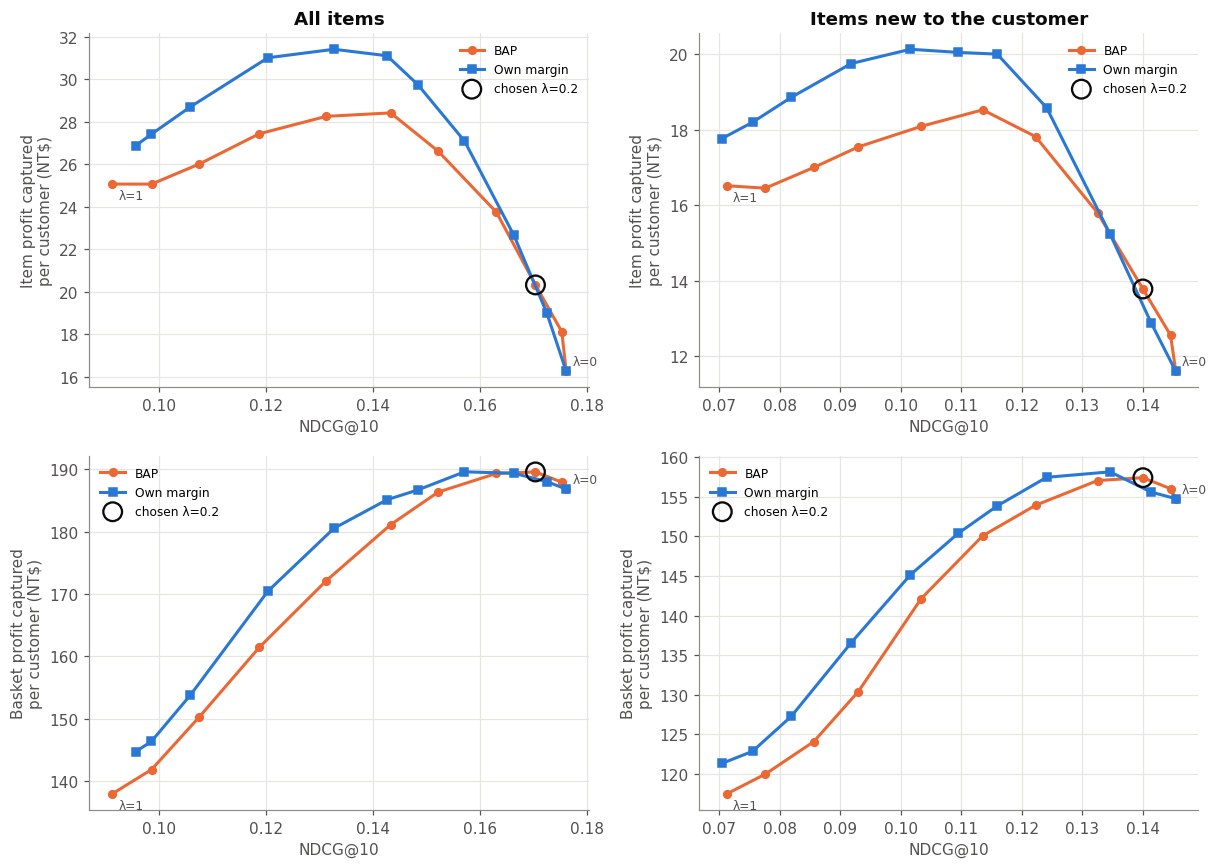

In [34]:
bap_val = bm.basket_adjusted_profit(val_ib, val_bk, min_baskets=MIN_BAP_BASKETS)
values_val = {"BAP": ev.item_values(bap_val, items_val, "bap"),
              "Own margin": ev.item_values(bap_val, items_val, "own_margin")}

sweeps_val, picks_val, cand_val = {}, {}, {}
for mode, title in [("all", "All items"), ("new", "Items new to the customer")]:
    cand_val[mode] = ev.candidates(best_val, test_val, mode)
    sweeps_val[title] = ev.lambda_sweep(cand_val[mode], test_val, values_val, mode)
    picks_val[title] = ev.pick_lambda(sweeps_val[title], "BAP")

print("chosen lambda (validation):", picks_val)
plots.profit_frontier(sweeps_val, picks_val, name="06a_profit_frontier_validation");

<p style="text-align:center"><b>Figure 11.</b> January validation results showing NDCG@10 and profit outcomes across re-ranking weights for BAP and own margin. The circles mark the selected weights.</p>

### Does Chinese New Year distort the tuning?

January is split into 1–13 January and 14–31 January to assess whether the selected re-ranking weight is sensitive to the period around Chinese New Year. The same λ sweep is repeated for each window. Since the dataset does not identify the reasons behind purchases, differences between the windows should be interpreted as period-related variation rather than evidence of specific holiday shopping motives.

,chosen lambda
1-13 Jan,0.1000
14-31 Jan (CNY),0.2000


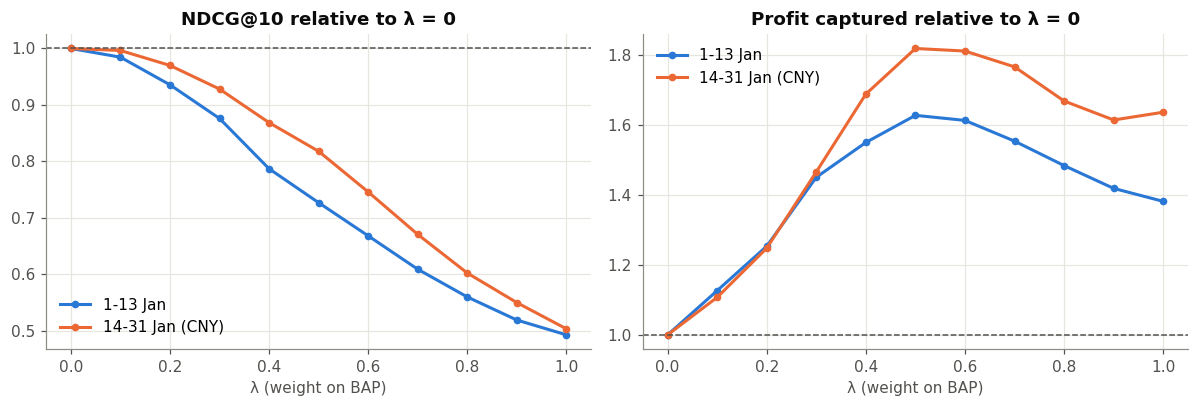

In [35]:
cny_sweeps, cny_picks = {}, {}
for title, (a, b) in {"1-13 Jan": (VAL_TRAIN_END, CNY_WINDOW_START),
                      "14-31 Jan (CNY)": (CNY_WINDOW_START, VAL_TEST_END)}.items():
    ts = ev.TestSet(R_val, users_val, items_val, dp.period(lines, a, b),
                    nb_val, MIN_TRAIN_BASKETS)
    c = ev.candidates(best_val, ts, "all")
    cny_sweeps[title] = ev.lambda_sweep(c, ts, values_val, "all")
    cny_picks[title] = ev.pick_lambda(cny_sweeps[title], "BAP")

display(pd.Series(cny_picks, name="chosen lambda").to_frame())
plots.cny_check(cny_sweeps);

<p style="text-align:center"><b>Figure 12.</b> NDCG@10 and item profit relative to the $\lambda=0$ baseline for the 1–13 January and 14–31 January evaluation windows.</p>

In [36]:
gap = abs(cny_picks["1-13 Jan"] - cny_picks["14-31 Jan (CNY)"])
say(f"The λ chosen on ordinary January weeks is "
    f"{cny_picks['1-13 Jan']:g} and on the New Year weeks "
    f"{cny_picks['14-31 Jan (CNY)']:g}. "
    + (("The two agree" if gap == 0 else
        "The two are within one step of the λ grid")
       + ", so **the holiday does not materially distort the tuning** and the "
       "full-January value is carried to the test."
       if gap <= 0.1 + 1e-9 else
       "They differ, so **the holiday shifts the trade-off**. To be safe, the "
       "test uses the λ chosen on the ordinary weeks, since February is not a "
       "holiday month."))
lam_choice = dict(picks_val)
if gap > 0.1:
    lam_choice["All items"] = cny_picks["1-13 Jan"]
print("lambda carried to the test:", lam_choice)

The λ chosen on ordinary January weeks is 0.1 and on the New Year weeks 0.2. The two are within one step of the λ grid, so **the holiday does not materially distort the tuning** and the full-January value is carried to the test.

lambda carried to the test: {'All items': 0.2, 'Items new to the customer': 0.2}


## Final Test: Train November–January, Test February

After validation, the selected models are refitted on November–January using the chosen settings. BAP is recalculated on the same training window for the store-level analysis and re-ranking. Recommendation relevance and profit metrics are then evaluated on February, which is not used to select model settings or re-ranking weights.

In [37]:
R, users, items = rc.build_utility(train_lines)
nb_train = baskets.groupby("customer").size()
test = ev.TestSet(R, users, items, hold_lines, nb_train, MIN_TRAIN_BASKETS)

final_models = [
    rc.Popularity().fit(R),
    rc.RepeatBuy().fit(R),
    rc.ItemKNN(best_knn.k).fit(R),
    rc.ImplicitALS(best_als.factors, alpha=best_als.alpha, seed=SEED).fit(R),
    rc.AssocRuleRec(pair_rules_train, items).fit(R),
]
model = next(m for m in final_models if m.name == best_name)
results = ev.evaluate_models(final_models, test)
results = results[~((results["model"] == "Repeat-buy")
                    & (results["mode"] == "new"))].reset_index(drop=True)
say(f"**{len(test.customers):,} customers** are evaluated in February "
    f"(utility matrix {R.shape[0]:,} × {R.shape[1]:,}).")
results

**10,197 customers** are evaluated in February (utility matrix 28,600 × 1,970).

,model,mode,customers,precision@10,recall@10,ndcg@10,profit_per_customer,basket_profit_per_customer,coverage
0,Popularity,all,10197,0.1589,0.1798,0.2000,7.9970,139.9626,0.0051
1,Popularity,new,9816,0.1012,0.1559,0.1465,2.9623,102.3989,0.0426
2,Repeat-buy,all,10197,0.2034,0.2311,0.2898,34.7148,167.2566,0.6538
3,Item-kNN (k=200),all,10197,0.1471,0.1508,0.1835,12.1443,140.5325,0.2645
4,Item-kNN (k=200),new,9816,0.1034,0.1582,0.1527,6.6314,110.4571,0.2604
5,"Implicit ALS (d=16, alpha=10)",all,10197,0.1586,0.1875,0.2134,21.2475,142.4658,0.1234
6,"Implicit ALS (d=16, alpha=10)",new,9816,0.0791,0.1249,0.1192,8.3775,93.2013,0.1355
7,FP-Growth rules,all,10197,0.1481,0.1627,0.1865,23.0059,148.2510,0.0614
8,FP-Growth rules,new,9816,0.0922,0.1421,0.1311,9.0389,106.5635,0.0650


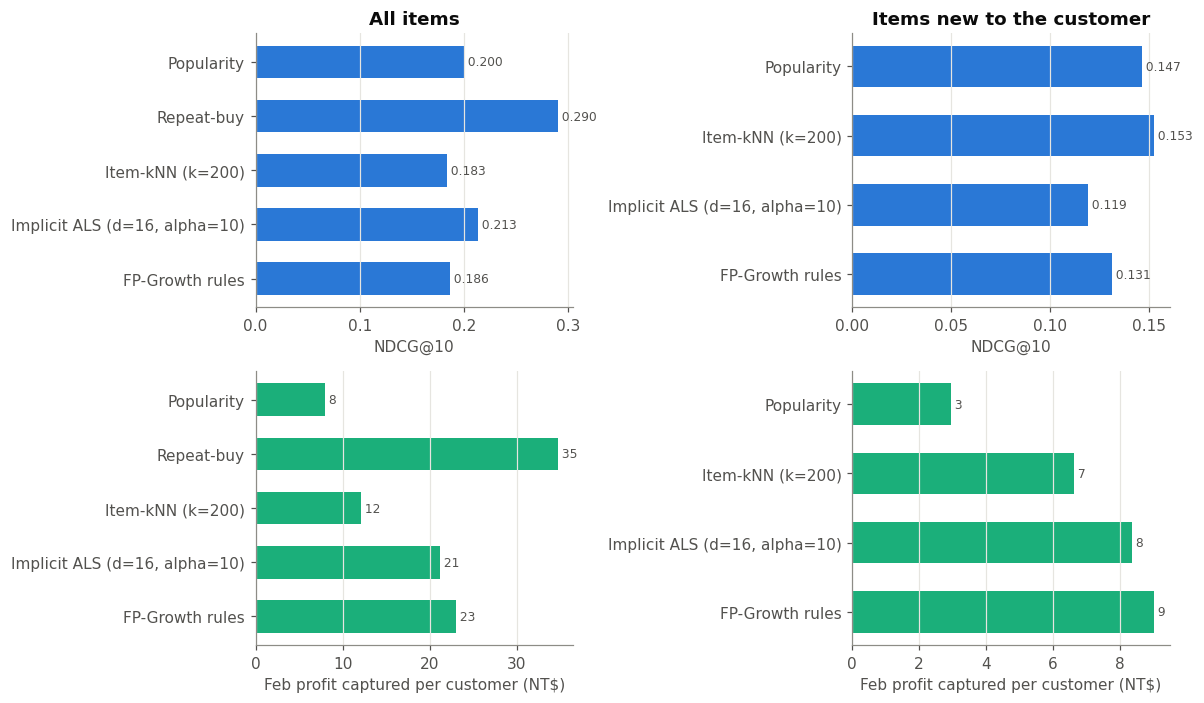

In [38]:
plots.model_comparison(results);

<p style="text-align:center"><b>Figure 13.</b> February test results showing NDCG@10 and profit captured per customer for each recommender, with all items eligible on the left and only new-to-customer items eligible on the right.</p>

In [39]:
res = results.set_index(["mode", "model"])
cf_names = [m.name for m in final_models[2:]]
best_all = res.loc["all", "ndcg@10"].idxmax()
best_new = res.loc["new", "ndcg@10"].idxmax()
pop_new = res.loc[("new", "Popularity"), "ndcg@10"]
cf_new = res.loc["new"].loc[cf_names, "ndcg@10"].max()
say(f"With all items allowed, the best model is **{best_all}** "
    f"(NDCG@10 {res.loc[('all', best_all), 'ndcg@10']:.3f}). "
    + ("Grocery demand is dominated by repeat purchases, so a customer's own "
       "history is very hard to beat on accuracy. "
       if best_all == "Repeat-buy" else "")
    + f"For items new to the customer, where the customer's history cannot help, "
    f"the best model is **{best_new}** "
    f"(NDCG@10 {res.loc[('new', best_new), 'ndcg@10']:.3f}), and the best CF "
    f"model reaches {cf_new / pop_new:.2f}× the NDCG of popularity. "
    + ("This is the setting where collaborative filtering earns its keep."
       if cf_new / pop_new >= 1.1 else
       "Discovery is hard in this data: CF gains little over simply "
       "recommending best-sellers.")
    + (f" Note that the selected model ({best_name}) was chosen on mean NDCG "
       f"across both settings; on all items it scores "
       f"{res.loc[('all', best_name), 'ndcg@10']:.3f}, below popularity "
       f"({res.loc[('all', 'Popularity'), 'ndcg@10']:.3f}), so for buy-again "
       f"lists the store should use repeat-buy and keep {best_name} for discovery."
       if res.loc[('all', best_name), 'ndcg@10'] < res.loc[('all', 'Popularity'), 'ndcg@10']
       else ""))

With all items allowed, the best model is **Repeat-buy** (NDCG@10 0.290). Grocery demand is dominated by repeat purchases, so a customer's own history is very hard to beat on accuracy. For items new to the customer, where the customer's history cannot help, the best model is **Item-kNN (k=200)** (NDCG@10 0.153), and the best CF model reaches 1.04× the NDCG of popularity. Discovery is hard in this data: CF gains little over simply recommending best-sellers. Note that the selected model (Item-kNN (k=200)) was chosen on mean NDCG across both settings; on all items it scores 0.183, below popularity (0.200), so for buy-again lists the store should use repeat-buy and keep Item-kNN (k=200) for discovery.

In [40]:
rules_name = final_models[-1].name
r_new = res.loc[("new", rules_name), "ndcg@10"]
best_cf_new = max(res.loc[("new", m.name), "ndcg@10"] for m in final_models[2:4])
if r_new >= best_cf_new:
    verdict = ("The rules match or beat CF here, so the same rules that explain "
               "the halo are also a strong, fully explainable recommender.")
elif r_new / pop_new >= 1.05:
    verdict = ("The rules that explain the halo also carry real predictive "
               "signal, but CF does better because it uses every co-purchase, "
               "not just pairs frequent enough to pass the support threshold.")
else:
    verdict = (("The rules barely beat popularity" if r_new >= pop_new else
                "The rules do not beat popularity")
               + ": frequent pairs are good at *explaining* baskets, but most of "
               "what a customer buys next is not covered by a rule strong enough "
               "to pass the support threshold, which is why CF, using every "
               "co-purchase, does better.")
say(f"The **FP-Growth rules recommender** reaches NDCG@10 {r_new:.3f} on new items, "
    f"{r_new / pop_new:.2f}× popularity and {r_new / best_cf_new:.2f}× the best "
    f"CF model. " + verdict)

The **FP-Growth rules recommender** reaches NDCG@10 0.131 on new items, 0.90× popularity and 0.86× the best CF model. The rules do not beat popularity: frequent pairs are good at *explaining* baskets, but most of what a customer buys next is not covered by a rule strong enough to pass the support threshold, which is why CF, using every co-purchase, does better.

### Who does each model serve?

Overall NDCG@10 can hide differences between customers with different amounts of purchase history. Customers are grouped by their number of November–January baskets, and each model's mean NDCG@10 is compared across the activity groups. This shows where performance varies with available history but does not establish why those differences occur.

activity                              2-3    4-6   7-12    13+
mode model                                                    
all  FP-Growth rules               0.1726 0.1810 0.2014 0.2552
     Implicit ALS (d=16, alpha=10) 0.1960 0.2063 0.2379 0.2863
     Item-kNN (k=200)              0.1587 0.1727 0.2113 0.3071
     Popularity                    0.1756 0.1912 0.2251 0.3208
     Repeat-buy                    0.2477 0.2790 0.3423 0.4564
new  FP-Growth rules               0.1347 0.1274 0.1269 0.1357
     Implicit ALS (d=16, alpha=10) 0.1166 0.1201 0.1197 0.1293
     Item-kNN (k=200)              0.1530 0.1483 0.1542 0.1663
     Popularity                    0.1458 0.1422 0.1470 0.1674

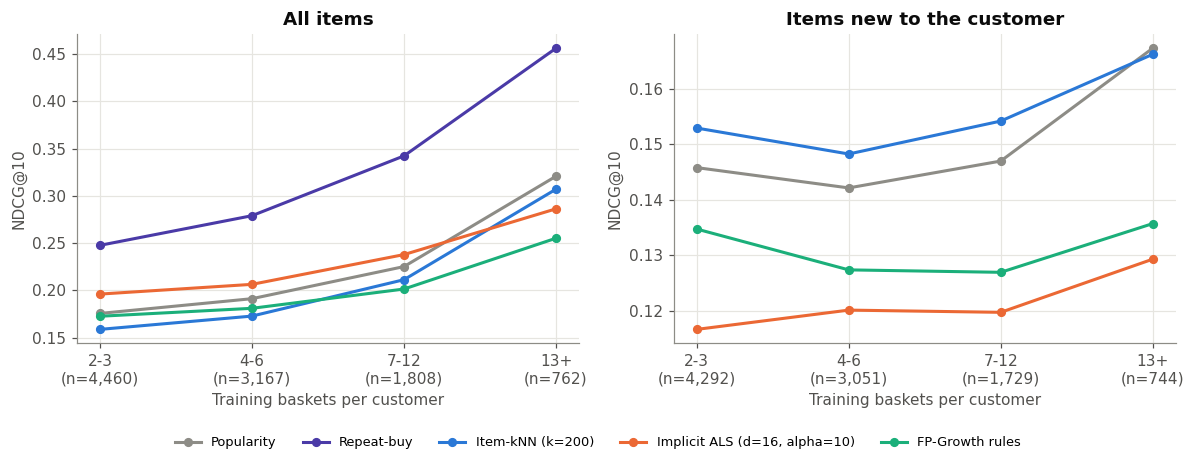

In [41]:
activity = ev.ndcg_by_activity(final_models, test, nb_train)
display(activity.pivot_table(index=["mode", "model"], columns="activity",
                             values="ndcg@10", observed=False))
plots.activity(activity);

<p style="text-align:center"><b>Figure 14.</b> Mean NDCG@10 by number of training baskets per customer, with group sizes shown. Repeat-buy is omitted from the new-items panel because its previously purchased items are removed, leaving it without distinct candidates for that task.</p>

In [42]:
new_act = activity[activity["mode"] == "new"].pivot_table(
    index="activity", columns="model", values="ndcg@10", observed=False)
lift_over_pop = new_act[best_new] / new_act["Popularity"]
all_act = activity[activity["mode"] == "all"].pivot_table(
    index="activity", columns="model", values="ndcg@10", observed=False)
best_all_light = all_act.iloc[0].idxmax()
best_all_heavy = all_act.iloc[-1].idxmax()
def vs_pop(r):
    return (f"{r - 1:.0%} above popularity" if r >= 1 else
            f"{1 - r:.0%} below popularity")

light, heavy = lift_over_pop.iloc[0], lift_over_pop.iloc[-1]
all_up = bool((all_act.iloc[-1] > all_act.iloc[0]).all())
txt = (f"On new items, **{best_new}** scores {vs_pop(light)} for the lightest "
       f"shoppers ({lift_over_pop.index[0]} baskets) and {vs_pop(heavy)} for the "
       f"most regular ones ({lift_over_pop.index[-1]}). ")
if light > heavy:
    txt += ("The gain over popularity is largest where a customer's own "
            "history is thinnest; one possible reason is that, for regulars, "
            "best-sellers they have not bought yet are already a strong guess. ")
else:
    txt += ("Collaborative filtering gains more as history grows, so its "
            "discovery value is concentrated on regular shoppers. ")
txt += (f"With all items allowed, the best model for light shoppers is "
        f"**{best_all_light}** and for regulars **{best_all_heavy}**"
        + (", and every model scores higher on regulars because there is more "
           "history to learn from." if all_up else "."))
say(txt)

On new items, **Item-kNN (k=200)** scores 5% above popularity for the lightest shoppers (2-3 baskets) and 1% below popularity for the most regular ones (13+). The gain over popularity is largest where a customer's own history is thinnest; one possible reason is that, for regulars, best-sellers they have not bought yet are already a strong guess. With all items allowed, the best model for light shoppers is **Repeat-buy** and for regulars **Repeat-buy**, and every model scores higher on regulars because there is more history to learn from.

### Profit-aware re-ranking on February

The validation-selected re-ranking weight (λ = 0.2) is applied to February without further tuning. BAP-based re-ranking is compared with own-margin re-ranking at the same weight to assess the trade-off between recommendation relevance, item profit, and basket profit.

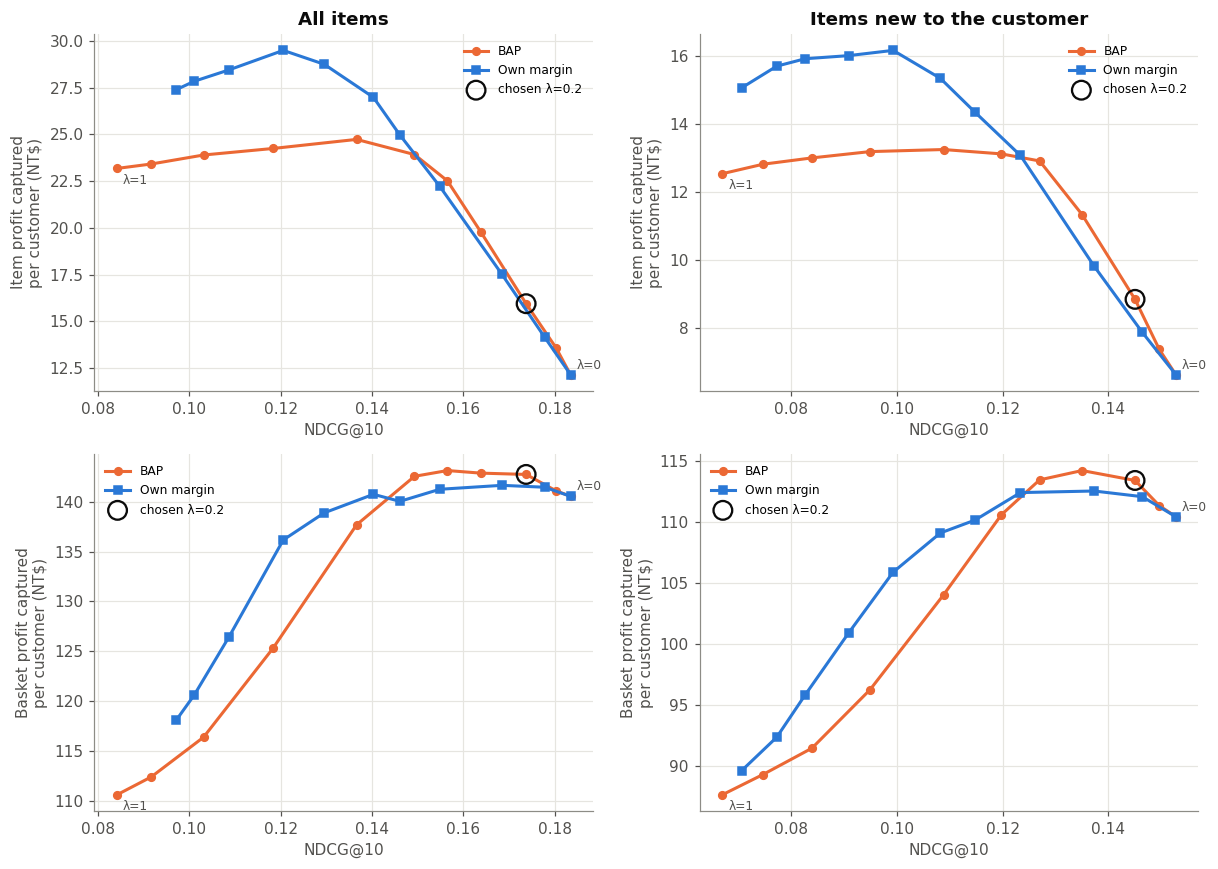

In [43]:
values = {"BAP": ev.item_values(bap, items, "bap"),
          "Own margin": ev.item_values(bap, items, "own_margin")}

sweeps, cand = {}, {}
for mode, title in [("all", "All items"), ("new", "Items new to the customer")]:
    cand[mode] = ev.candidates(model, test, mode)
    sweeps[title] = ev.lambda_sweep(cand[mode], test, values, mode)

plots.profit_frontier(sweeps, lam_choice, name="06b_profit_frontier_test");

<p style="text-align:center"><b>Figure 15.</b> February test accuracy–profit trade-off for BAP-based and own-margin-based re-ranking. The circles mark the validation-selected weight, λ = 0.2.</p>

In [44]:
rows = []
for mode, title in [("all", "All items"), ("new", "Items new to the customer")]:
    sw, lam = sweeps[title], lam_choice[title]
    for sig in ["BAP", "Own margin"]:
        r0 = sw[(sw["signal"] == sig) & (sw["lambda"] == 0)].iloc[0]
        r1 = sw[(sw["signal"] == sig) & (sw["lambda"] == lam)].iloc[0]
        rows.append({
            "setting": title, "signal": sig, "lambda": lam,
            "ndcg@10": r1["ndcg@10"],
            "ndcg change": r1["ndcg@10"] / r0["ndcg@10"] - 1,
            "item profit change": r1["profit_per_customer"]
                                  / r0["profit_per_customer"] - 1,
            "basket profit change": r1["basket_profit_per_customer"]
                                    / r0["basket_profit_per_customer"] - 1,
        })
rerank_table = pd.DataFrame(rows)
rerank_table

,setting,signal,lambda,ndcg@10,ndcg change,item profit change,basket profit change
0,All items,BAP,0.2000,0.1737,-0.0530,0.3124,0.0156
1,All items,Own margin,0.2000,0.1684,-0.0818,0.4420,0.0078
2,Items new to the customer,BAP,0.2000,0.1450,-0.0505,0.3334,0.0269
3,Items new to the customer,Own margin,0.2000,0.1373,-0.1013,0.4807,0.0191


In [45]:
def _row(setting, signal):
    return rerank_table[(rerank_table["setting"] == setting)
                        & (rerank_table["signal"] == signal)].iloc[0]

txt = []
for setting in ["All items", "Items new to the customer"]:
    b, m = _row(setting, "BAP"), _row(setting, "Own margin")
    txt.append(
        f"* **{setting}** (λ = {b['lambda']:g}): BAP re-ranking changes NDCG@10 "
        f"by {b['ndcg change']:+.1%}, item profit by {b['item profit change']:+.1%} "
        f"and basket profit by {b['basket profit change']:+.1%}; the margin-only "
        f"control at the same λ gives {m['item profit change']:+.1%} item profit "
        f"and {m['basket profit change']:+.1%} basket profit.")
say("\n".join(txt))

* **All items** (λ = 0.2): BAP re-ranking changes NDCG@10 by -5.3%, item profit by +31.2% and basket profit by +1.6%; the margin-only control at the same λ gives +44.2% item profit and +0.8% basket profit.
* **Items new to the customer** (λ = 0.2): BAP re-ranking changes NDCG@10 by -5.1%, item profit by +33.3% and basket profit by +2.7%; the margin-only control at the same λ gives +48.1% item profit and +1.9% basket profit.

Own-margin re-ranking directly prioritizes the profit of each recommended item. BAP also incorporates the measured halo of the surrounding basket. The February comparison tests whether BAP improves measured basket profit relative to the own-margin control while maintaining recommendation relevance. Any gain is an offline result, not evidence that a live recommendation would cause additional spending.

## Segments: Age Groups and Chinese New Year

Pair rules are mined separately by age group and time period using a 0.5% support threshold within each segment. The 20 highest-lift pairs are compared using Jaccard overlap, $\vert{}A\cap B\vert{}/\vert{}A\cup B\vert{}$. Lower overlap indicates that the highest-ranked associations differ between segments. This may motivate testing segment-specific merchandising, but it does not establish that targeted promotions outperform store-wide promotions.

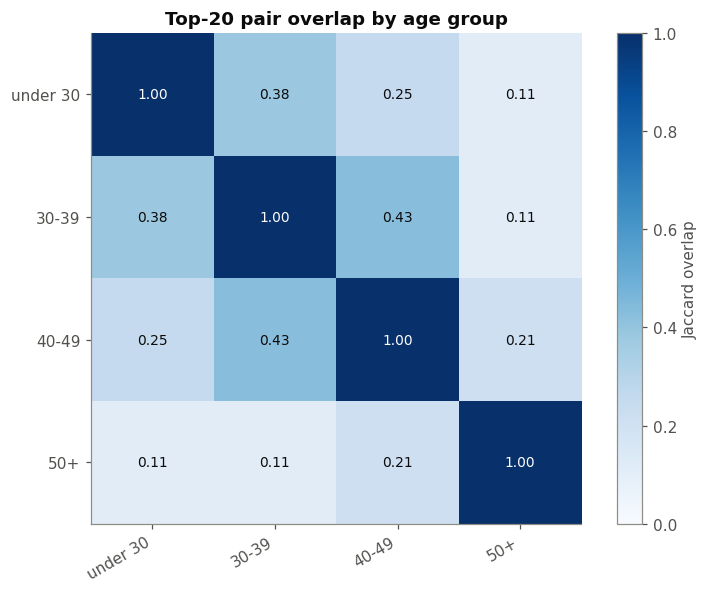

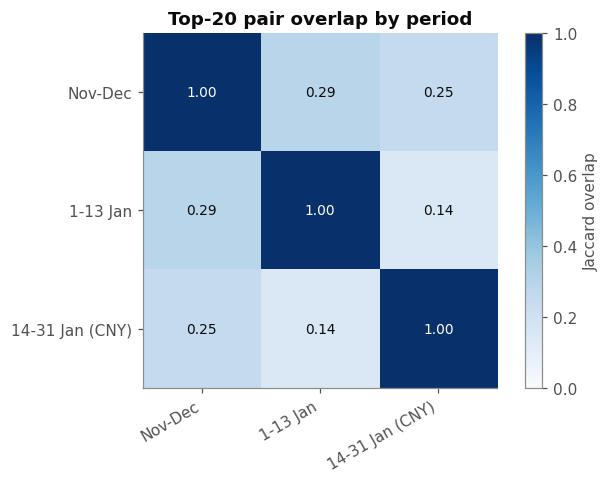

In [46]:
age_band = baskets["age"].astype(str).map({
    "<25": "under 30", "25-29": "under 30",
    "30-34": "30-39", "35-39": "30-39",
    "40-44": "40-49", "45-49": "40-49",
    "50-54": "50+", "55-59": "50+", "60-64": "50+", ">64": "50+",
})
age_groups = {g: (age_band == g).to_numpy()
              for g in ["under 30", "30-39", "40-49", "50+"]}
age_top, age_overlap = bm.segment_rules(item_basket, baskets, age_groups,
                                        SEGMENT_SUPPORT)

cny_start = pd.Timestamp(CNY_WINDOW_START)
time_groups = {
    "Nov-Dec": (baskets["date"] < pd.Timestamp(VAL_TRAIN_END)).to_numpy(),
    "1-13 Jan": ((baskets["date"] >= pd.Timestamp(VAL_TRAIN_END))
                 & (baskets["date"] < cny_start)).to_numpy(),
    "14-31 Jan (CNY)": (baskets["date"] >= cny_start).to_numpy(),
}
time_top, time_overlap = bm.segment_rules(item_basket, baskets, time_groups,
                                          SEGMENT_SUPPORT)
plots.segment_overlap(age_overlap, "Top-20 pair overlap by age group",
                      "08a_segments_age");
plots.segment_overlap(time_overlap, "Top-20 pair overlap by period",
                      "08b_segments_time");

<p style="text-align:center"><b>Figure 16–17.</b> Jaccard overlap of the 20 highest-lift pair rules across age groups and time periods, respectively. Values closer to 1 indicate more shared pairs; values closer to 0 indicate fewer shared pairs.</p>

In [47]:
# pairs that are top-20 in exactly one segment: what makes a segment distinct
def distinct_pairs(top, n=3):
    counts = top["pair"].value_counts()
    own = top[top["pair"].map(counts) == 1]
    return (own.sort_values("lift", ascending=False).groupby("segment").head(n)
            [["segment", "baskets", "antecedent", "consequent", "lift",
              "rel_support"]])

display(distinct_pairs(age_top))
display(distinct_pairs(time_top))

,segment,baskets,antecedent,consequent,lift,rel_support
0,under 30,11925,"(320402,)",320501,62.6390,0.0065
3,under 30,11925,"(530111,)",530110,10.2917,0.0058
22,30-39,32168,"(130302,)",120103,7.6134,0.0053
45,40-49,24934,"(110506,)",110507,6.6788,0.0055
28,30-39,32168,"(120103,)",120115,6.0330,0.0050
11,under 30,11925,"(560405,)",560201,5.7964,0.0051
65,50+,16160,"(530110,)",530105,4.9079,0.0052
36,30-39,32168,"(120106,)",120103,4.6798,0.0056
68,50+,16160,"(100217,)",100205,4.4815,0.0062
69,50+,16160,"(100205,)",100210,4.4533,0.0058


,segment,baskets,antecedent,consequent,lift,rel_support
40,14-31 Jan (CNY),20322,"(320402,)",320501,38.5226,0.0092
41,14-31 Jan (CNY),20322,"(110810,)",110811,15.5496,0.0053
47,14-31 Jan (CNY),20322,"(100305,)",100304,8.3029,0.0071
3,Nov-Dec,58540,"(130302,)",120103,7.3900,0.0051
28,1-13 Jan,9532,"(110410,)",110401,6.0917,0.0050
29,1-13 Jan,9532,"(560201,)",560405,5.6984,0.0051
30,1-13 Jan,9532,"(110117,)",110118,5.6962,0.0051
13,Nov-Dec,58540,"(110119,)",120103,5.4798,0.0063
15,Nov-Dec,58540,"(500203,)",500210,4.2307,0.0070


In [48]:
off = lambda o: o.values[np.triu_indices(len(o), 1)].mean()
say(f"The average overlap of top pairs between age groups is "
    f"**{off(age_overlap):.2f}** and between periods **{off(time_overlap):.2f}**. "
    f"Low overlap means the strongest associations differ between segments, "
    f"which motivates testing segment-specific merchandising or personalised "
    f"offers; it does not show that they would outperform a store-wide promotion.")

The average overlap of top pairs between age groups is **0.25** and between periods **0.23**. Low overlap means the strongest associations differ between segments, which motivates testing segment-specific merchandising or personalised offers; it does not show that they would outperform a store-wide promotion.

## Action List for the Store

The tables below translate the analysis into product-review, bundle-testing, and recommendation candidates. The thresholds determine which subclasses qualify; they do not prove that a price change or promotion will cause a particular profit outcome.

**1. Retention candidates.** No subclass passes the current strict retention filter, which requires positive BAP and a halo at least two standard errors above zero. Three subclasses are classified as loss leaders under the below-cost median-halo rule, but none meets this stricter threshold. The six subclasses identified by the separate non-negative-BAP sensitivity criterion should not be treated as confirmed keep candidates.

In [49]:
keep = lead[(lead["bap"] > 0) & (lead["halo_t"] >= 2)].sort_values("bap",
                                                                    ascending=False)
if len(pull):
    top_pull = (pull.groupby("leader")["consequent"]
                .apply(lambda s: ", ".join(s.head(3))))
    keep = keep.assign(pulls_in=top_pull.reindex(keep.index).fillna("-"))
show_cols = ["quadrant", "n_baskets", "own_margin", "halo", "halo_t", "bap",
             "breakeven_share"]
if len(keep):
    robust = keep[keep["breakeven_share"] < 0.25]
    say(f"**{len(keep):,} subclasses** pass the strict filter. Their below-cost "
        f"sales lost NT${-keep['profit'].sum():,.0f} over November–January, and "
        f"**{len(robust):,} have a break-even share below 25%**: under the "
        f"sensitivity model they would remain worthwhile even if only a quarter "
        f"of their halo were causal. These are candidates for a controlled test, "
        f"not confirmed keeps.")
    display(keep[show_cols[1:] + (["pulls_in"] if "pulls_in" in keep else [])].head(15))
else:
    sens = bap_loss[bap_loss["bap"] >= 0].sort_values("bap", ascending=False)
    say(f"**No subclass passes the strict retention filter.** For transparency, "
        f"the {len(sens):,} subclasses whose below-cost sales have non-negative "
        f"BAP are listed below; none has a halo two standard errors above zero, "
        f"so they are sensitivity-analysis cases, not keep recommendations.")
    display(sens[show_cols])

**No subclass passes the strict retention filter.** For transparency, the 6 subclasses whose below-cost sales have non-negative BAP are listed below; none has a halo two standard errors above zero, so they are sensitivity-analysis cases, not keep recommendations.

,quadrant,n_baskets,own_margin,halo,halo_t,bap,breakeven_share
subclass,,,,,,,
530405,Loss leader,74,-8.6216,72.7503,0.7033,64.1287,0.1185
500317,Loss leader,50,-10.8400,40.8659,1.1543,30.0259,0.2653
530401,Loss leader,106,-20.1226,35.7804,1.9776,15.6578,0.5624
500307,Dead weight,270,-9.6111,18.2389,0.5857,8.6278,0.5270
760523,Dead weight,84,-1.3214,8.3554,0.2385,7.0340,0.1582
500212,Dead weight,67,-8.5373,11.0372,0.6268,2.4999,0.7735


**2. Review below-cost sales with non-positive halos.** Prioritize subclasses whose below-cost sales have a halo at or below zero for pricing and assortment review. Their observed baskets do not exceed the size-adjusted benchmark on this measure. However, this does not guarantee that removing the sales would preserve all other purchases or profits.

In [50]:
drop = dead[dead["halo"] <= 0].sort_values("bap")
overall_losers = list(loss_subclasses.index)
say(f"**{len(drop):,} subclasses** qualify; their below-cost sales lost "
    f"NT${-drop['profit'].sum():,.0f} over November–January. Their baskets "
    f"earn at or below the size-adjusted benchmark, so this measure shows no "
    f"offsetting basket benefit from these below-cost sales; the actual effect "
    f"of repricing them would still need to be tested. "
    + (f"Separately, {len(overall_losers):,} subclass(es) lose money even on "
       f"average ({', '.join(overall_losers[:5])}"
       + (", ..." if len(overall_losers) > 5 else "")
       + ") and are candidates for a full price review." if overall_losers else ""))
drop[["n_baskets", "own_margin", "margin_rate", "halo", "bap"]].head(15)

**111 subclasses** qualify; their below-cost sales lost NTD 576,759 over November–January. Their baskets earn at or below the size-adjusted benchmark, so this measure shows no offsetting basket benefit from these below-cost sales; the actual effect of repricing them would still need to be tested. Separately, 5 subclass(es) lose money even on average (110217, 110106, 130315, 340101, 711409) and are candidates for a full price review.

,n_baskets,own_margin,margin_rate,halo,bap
subclass,,,,,
560402,340,-93.5794,-0.1209,-36.0220,-129.6014
100510,41,-25.8049,-0.1536,-97.7107,-123.5156
100504,53,-17.4528,-0.1032,-95.1381,-112.5909
110506,35,-24.8286,-0.1176,-86.4944,-111.3230
100503,38,-8.3947,-0.0743,-101.6052,-109.9999
110305,38,-2.2895,-0.0256,-106.4811,-108.7706
100310,66,-6.8030,-0.0508,-101.6157,-108.4187
130102,113,-5.2566,-0.1115,-101.3104,-106.5670
130207,64,-2.7969,-0.0873,-103.0122,-105.8091


**3. Test bundle candidates.** Prioritize pairs with lift of at least 1.5, positive combined own margin, and recurring basket support. The highest-ranked pairs are candidates for a controlled bundle or placement trial. Compare incremental profit with an appropriate baseline before adopting them permanently.

In [51]:
bundles.head(10)[["a", "b", "quad_a", "quad_b", "support", "lift", "pair_margin"]]

,a,b,quad_a,quad_b,support,lift,pair_margin
0,320402,320501,Star,Star,399,61.4091,554.3725
1,560201,560402,Passenger,Passenger,1073,6.0346,91.7095
2,530110,530114,Passenger,Passenger,848,7.1054,66.6750
3,530101,530103,Passenger,Passenger,1047,7.4447,42.4696
4,560402,560405,Passenger,Passenger,447,11.4183,64.3351
5,530104,530105,Star,Passenger,731,7.8150,55.1426
6,530110,530111,Passenger,Passenger,370,10.4053,68.6325
7,560201,560204,Passenger,Passenger,692,5.9399,54.4652
8,100402,100403,Passenger,Passenger,279,17.2450,46.4914
9,120103,120104,Passenger,Passenger,636,9.0104,37.7845


**4. Pilot personalized offers.** The selected recommender generates up to 50 new-to-customer candidates per customer and re-ranks them using BAP at the validation-selected λ. The notebook displays five example customers and generates offers for all evaluated customers. Since the data uses subclass codes rather than product names, codes and availability should be mapped before a campaign. Use a holdout group to measure incremental profit and customer response.

In [52]:
lam_new = lam_choice["Items new to the customer"]
offers_idx = ev.rerank(cand["new"], values["BAP"], lam_new, n=5)
offers = pd.DataFrame(items.to_numpy()[offers_idx], index=test.customers,
                      columns=[f"offer {i + 1}" for i in range(5)])
quad_of = bap["quadrant"].reindex(items).fillna("unscored").to_numpy()
mix = pd.Series(quad_of[offers_idx].ravel()).value_counts(normalize=True)

mix = mix[mix >= 0.005]
say(f"Across all {len(offers):,} customers, the top-5 offers (λ = {lam_new:g}) "
    f"are drawn from these all-sales quadrants: "
    + ", ".join(f"{q.lower()} {share:.0%}" for q, share in mix.items())
    + ". Each customer receives a different set."
    + (" Here *dead weight* means the all-sales quadrant, i.e. subclasses that "
       "lose money on average; excluding them from offers would be a simple "
       "safeguard." if "Dead weight" in mix.index else ""))
offers.sample(5, random_state=SEED)

Across all 10,197 customers, the top-5 offers (λ = 0.2) are drawn from these all-sales quadrants: passenger 95%, dead weight 3%, star 2%. Each customer receives a different set. Here *dead weight* means the all-sales quadrant, i.e. subclasses that lose money on average; excluding them from offers would be a simple safeguard.

,offer 1,offer 2,offer 3,offer 4,offer 5
1970777,530105,100102,110411,530114,500210
549189,560402,560204,100102,530101,100201
1742435,560402,530101,500201,100205,110401
2113579,100401,100503,100304,100515,100110
1058543,100205,110401,100505,130206,500201


## Results at a Glance

The summary below reports the main data-quality, BAP, delisting-sensitivity, and recommender results from this run. Counts and metrics are generated from the current notebook outputs and will update when the data or settings change.

In [53]:
b_all, b_new = _row("All items", "BAP"), _row("Items new to the customer", "BAP")
glance = [
    f"* **Data**: {len(lines):,} clean lines; {n_baskets:,} training baskets; "
    f"{len(bap):,} subclasses scored.",
    f"* **Line totals**: {'confirmed' if is_total else 'not confirmed'}; "
    f"{below_cost:.1%} of clean lines sell below cost.",
    f"* **FIM**: {len(supports):,} frequent itemsets and {len(rules):,} rules "
    f"at {MIN_SUPPORT:.1%} support.",
    f"* **BAP**: {len(bap):,} subclasses scored and only {len(loss_subclasses):,} "
    f"lose money on average, though {line_loss_share:.1%} of lines sell below "
    f"cost. Scoring the below-cost sales: {len(lead):,} loss leaders "
    f"({(lead['bap'] > 0).sum():,} with positive BAP) and {len(dead):,} dead "
    f"weight. Halo rank correlation between training and February = "
    f"{persist['halo']:.2f}.",
    f"* **Size baseline**: link between halo and basket size drops from "
    f"ρ = {bias.iloc[0]:.2f} (naive) to {bias.iloc[1]:.2f} (adjusted); "
    f"{flips:,} subclasses would change quadrant without it.",
    (f"* **Ending below-cost sales**: stopping all of them beats the BAP rule "
     f"only if less than {crossover:.0%} of the kept sales' halo is causal."
     if crossover is not None else
     "* **Ending below-cost sales**: all have negative BAP, so both rules agree."),
    f"* **Recommender (February)**: best accuracy with all items = {best_all}; "
    f"best for new items = {best_new}; selected CF model = {best_name}; "
    f"FP-Growth rules reach {r_new / pop_new:.2f}× popularity on new items.",
    f"* **Profit-aware re-ranking**: all items, λ = {b_all['lambda']:g}: NDCG "
    f"{b_all['ndcg change']:+.1%}, item profit {b_all['item profit change']:+.1%}, "
    f"basket profit {b_all['basket profit change']:+.1%}. New items, "
    f"λ = {b_new['lambda']:g}: NDCG {b_new['ndcg change']:+.1%}, item profit "
    f"{b_new['item profit change']:+.1%}, basket profit "
    f"{b_new['basket profit change']:+.1%}.",
    (f"* **Actions**: {len(keep):,} below-cost sales pass the strict retention "
     f"filter" if len(keep) else
     "* **Actions**: no below-cost sales pass the strict retention filter")
    + f"; {len(drop):,} subclasses' below-cost sales prioritised for pricing "
    f"review; {min(10, len(bundles))} bundle candidates to test; personalised "
    f"offers generated for {len(offers):,} customers.",
]
say("\n".join(glance))

* **Data**: 817,149 clean lines; 88,394 training baskets; 1,121 subclasses scored.
* **Line totals**: confirmed; 7.7% of clean lines sell below cost.
* **FIM**: 1,066 frequent itemsets and 1,422 rules at 0.3% support.
* **BAP**: 1,121 subclasses scored and only 5 lose money on average, though 7.7% of lines sell below cost. Scoring the below-cost sales: 3 loss leaders (3 with positive BAP) and 121 dead weight. Halo rank correlation between training and February = 0.79.
* **Size baseline**: link between halo and basket size drops from ρ = 0.62 (naive) to 0.13 (adjusted); 206 subclasses would change quadrant without it.
* **Ending below-cost sales**: stopping all of them beats the BAP rule only if less than 37% of the kept sales' halo is causal.
* **Recommender (February)**: best accuracy with all items = Repeat-buy; best for new items = Item-kNN (k=200); selected CF model = Item-kNN (k=200); FP-Growth rules reach 0.90× popularity on new items.
* **Profit-aware re-ranking**: all items, λ = 0.2: NDCG -5.3%, item profit +31.2%, basket profit +1.6%. New items, λ = 0.2: NDCG -5.1%, item profit +33.3%, basket profit +2.7%.
* **Actions**: no below-cost sales pass the strict retention filter; 111 subclasses' below-cost sales prioritised for pricing review; 10 bundle candidates to test; personalised offers generated for 10,197 customers.

## Limitations

- **Association, not causation.** BAP measures observed basket association. The delisting analysis varies an assumed causal share; it does not estimate the true share. A controlled pricing or delisting test is needed to estimate causal effects.
- **Subclass-level data.** Subclasses pool brands and pack sizes, and the dataset supplies codes rather than product names. Product codes must be mapped before operational decisions.
- **Short observation period.** Four months from one store cannot establish long-run effects or generalize across stores and seasons.
- **Offline evaluation.** Recommendation metrics use historical purchases made without exposure to the recommendations. They measure alignment with observed behavior, not response to offers or incremental profit.
- **Rare items.** Subclasses with fewer than 30 training baskets receive no individual BAP score and are assigned the median value during re-ranking.

## Conclusion

Own margin alone does not capture how a subclass is associated with the profitability of its surrounding basket. BAP provides a complementary descriptive measure, while FP-Growth identifies recurring co-purchase patterns and candidate pairs for bundle testing. However, no subclass passes the strict retention screen in this run, so the analysis does not support a definitive recommendation to keep any below-cost sale on the basis of the stated criteria. The clearest result points the other way: over 99% of the losses from below-cost sales (NTD 614,236 of NTD 617,549) occur in baskets that earn no more than a typical item's, so the evidence supports reviewing below-cost pricing rather than defending it as a loss-leader strategy. The delisting sensitivity analysis shows how the comparison between the margin and BAP rules depends on the assumed causal share of the halo.

For recommendations, repeat-buy remains the strongest model when previously purchased items are eligible. Item-kNN achieves only a modest improvement over popularity on new-to-customer items. BAP-based re-ranking produces a larger measured basket-profit gain than the own-margin control, while own margin produces larger item-profit gains. These are offline results; controlled trials are needed to determine whether either approach improves actual store profit.

The practical next step is to prioritize product reviews and test the strongest bundle and recommendation candidates, rather than treating the observational results as proof of causal gains.

In [54]:
verdict = []
for setting in ["All items", "Items new to the customer"]:
    b, m = _row(setting, "BAP"), _row(setting, "Own margin")
    lever_item = "BAP" if b["item profit change"] > m["item profit change"] else "own margin"
    lever_basket = "BAP" if b["basket profit change"] > m["basket profit change"] else "own margin"
    verdict.append(f"* **{setting}**: {lever_item} raises item profit more; "
                   f"{lever_basket} raises basket profit more.")
adds = all(_row(s_, "BAP")["basket profit change"]
           > _row(s_, "Own margin")["basket profit change"]
           for s_ in ["All items", "Items new to the customer"])
smaller_drop = all(_row(s_, "BAP")["ndcg change"] > _row(s_, "Own margin")["ndcg change"]
                   for s_ in ["All items", "Items new to the customer"])
verdict.append("\n" + (("**In this offline comparison, BAP re-ranking shows the larger "
                        "basket-profit gain"
                        + (" and the smaller NDCG@10 decline" if smaller_drop else "")
                        + "**, while own margin shows the larger item-profit gain. "
                        "This describes historical purchases, not the causal lift of a "
                        "live campaign.")
                       if adds else
                       "**BAP re-ranking does not consistently beat the own-margin "
                       "control** on basket profit in this offline test."))
say("\n".join(verdict))

* **All items**: own margin raises item profit more; BAP raises basket profit more.
* **Items new to the customer**: own margin raises item profit more; BAP raises basket profit more.

**In this offline comparison, BAP re-ranking shows the larger basket-profit gain and the smaller NDCG@10 decline**, while own margin shows the larger item-profit gain. This describes historical purchases, not the causal lift of a live campaign.

**Recommendations:** prioritize the 111 subclasses whose below-cost sales have non-positive halos for pricing and assortment review. Do not make a blanket retention recommendation, because no subclass passes the current strict keep filter. Treat the six non-negative-BAP cases as sensitivity-analysis candidates rather than proven loss leaders worth keeping. Test high-ranked bundles and BAP-based recommendations with holdout groups, and compare incremental profit and customer response before scaling any intervention.

# References

* C. Aggarwal, "Data Mining: The Textbook", Springer, 2015.
* C. Aggarwal, "Recommender Systems: The Textbook", Springer, 2016.
* J. Leskovec, A. Rajaraman and J. Ullman, "Mining of Massive Datasets", 3rd ed., Cambridge University Press, 2020.
* C. Borgelt, "Frequent item set mining", WIREs Data Mining and Knowledge Discovery, 2(6), 437–456, 2012 (pyFIM).
* Y. Hu, Y. Koren and C. Volinsky, "Collaborative Filtering for Implicit Feedback Datasets", Proc. IEEE ICDM, 263–272, 2008.
* M. Deshpande and G. Karypis, "Item-based top-N recommendation algorithms", ACM Transactions on Information Systems, 22(1), 143–177, 2004.
* R. Lal and C. Matutes, "Retail Pricing and Advertising Strategies", Journal of Business, 67(3), 345–370, 1994 (loss-leader pricing).
* C.-N. Hsu, H.-H. Chung and H.-S. Huang, "Mining skewed and sparse transaction data for personalized shopping recommendation", Machine Learning, 57, 35–59, 2004 (Ta Feng dataset).